<a href="https://colab.research.google.com/github/junelwc6-source/IBM-HR-Attrition-Analytics/blob/main/IBM_HR_Attrition_Capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Part 1 - Descriptive Analytics**


### 1. Project Overview

**Project Title:** Employee Attrition Analysis and Prediction

**BProblem Statement:**

How can employee data be analysed to identify key factors associated with employee attrition, predict employees' likelihood of leaving, and support targeted retention strategies and proactive workforce planning to reduce attrition and minimise staffing gaps?

**Dataset:**

IBM HR Analytics Employee Attrition Dataset, comprising five datasets covering employee demographics, compensation, performance, work experience and employment status.



## 2. Data Loading and Understanding

### Objective

To load and examine the five IBM HR Analytics datasets, understand their structure and identify the variables available for employee attrition analysis.

### Data Sources

The analysis uses five datasets:

1. **Employees** – Employee demographics, department and job role.
2. **Compensation** – Salary and compensation information.
3. **Performance** – Job satisfaction, work-life balance and performance indicators.
4. **Experience** – Employment tenure, work experience and career progression.
5. **Employment Status** – Employee attrition and overtime status.



In [196]:

import pandas as pd

# GitHub repository location
base_url = "https://raw.githubusercontent.com/junelwc6-source/IBM-HR-Attrition-Analytics/main/"

# Load datasets directly from GitHub
employees = pd.read_csv(base_url + "Employees.csv")
compensation = pd.read_csv(base_url + "Compensation.csv")
performance = pd.read_csv(base_url + "Performance.csv")
experience = pd.read_csv(base_url + "Experience.csv")
employment_status = pd.read_csv(
    base_url + "Employment%20Status.csv"
)

# Check datasets loaded successfully
print("Employees:", employees.shape)
print("Compensation:", compensation.shape)
print("Performance:", performance.shape)
print("Experience:", experience.shape)
print("Employment Status:", employment_status.shape)


Employees: (1470, 14)
Compensation: (1470, 7)
Performance: (1470, 7)
Experience: (1470, 8)
Employment Status: (1470, 3)


In [197]:

# Check data quality for all five datasets

datasets = {
    "Employees": employees,
    "Compensation": compensation,
    "Performance": performance,
    "Experience": experience,
    "Employment Status": status
}

for name, df in datasets.items():
    print("\n", name)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())



 Employees
Missing values: 5
Duplicate Employee IDs: 0

 Compensation
Missing values: 0
Duplicate Employee IDs: 0

 Performance
Missing values: 0
Duplicate Employee IDs: 0

 Experience
Missing values: 0
Duplicate Employee IDs: 0

 Employment Status
Missing values: 0
Duplicate Employee IDs: 0



## 3. Data Cleaning and Integration

### Objective

To identify and address data quality issues, validate employee records and merge the five datasets into a single dataset for analysis.

### Data Cleaning

The datasets were checked for missing values and data consistency. Five missing values were identified in the Age column of the Employees dataset. These were replaced with the median age of 36 to retain all employee records for descriptive analysis.


In [198]:

# Identify columns with missing values
print(employees.isnull().sum())

# Display records containing missing values
display(employees[employees.isnull().any(axis=1)])


EmployeeNumber      0
Age                 5
Gender              0
MaritalStatus       0
Education           0
EducationField      0
Department          0
JobRole             0
JobLevel            0
BusinessTravel      0
DistanceFromHome    0
EmployeeCount       0
Over18              0
StandardHours       0
dtype: int64


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,DistanceFromHome,EmployeeCount,Over18,StandardHours
5,8,NaN,Male,Single,2,Life Sciences,Research & Development,Laboratory Technician,1,Travel_Frequently,2,1,Y,80
27,35,NaN,Male,Married,4,Marketing,Sales,Sales Executive,2,Travel_Rarely,8,1,Y,80
134,177,NaN,Female,Married,1,Life Sciences,Human Resources,Human Resources,1,Travel_Rarely,25,1,Y,80
262,362,NaN,Male,Single,1,Technical Degree,Research & Development,Laboratory Technician,2,Travel_Rarely,2,1,Y,80
377,501,NaN,Female,Married,3,Life Sciences,Research & Development,Research Scientist,1,Travel_Rarely,2,1,Y,80


In [199]:

# Standardise gender values before data integration

employees["Gender"] = (
    employees["Gender"]
    .str.strip()
    .str.lower()
    .replace({
        "m": "male",
        "f": "female",
        "femal": "female"
    })
    .str.title()
)

# Verify cleaned gender categories
print(employees["Gender"].value_counts())


Gender
Male      882
Female    588
Name: count, dtype: int64


In [200]:

# Check the median age before cleaning
print("Median Age:", employees["Age"].median())

# Replace missing ages with the median age
employees["Age"] = employees["Age"].fillna(
    employees["Age"].median()
)

# Verify that no missing values remain
print("Missing Age values after cleaning:",
      employees["Age"].isnull().sum())


Median Age: 36.0
Missing Age values after cleaning: 0


### Data Cleaning – Missing Values

The initial data quality check identified five missing values in the Age column of the Employees dataset, representing approximately 0.34% of the 1,470 employee records.

The missing values were replaced using the median age to retain all employee records and minimise the influence of extreme values.

No duplicate Employee IDs were identified across the five datasets.

In [201]:

# Check whether Employee IDs match across all datasets

employee_ids = set(employees["EmployeeNumber"])

for name, df in datasets.items():
    ids = set(df["EmployeeNumber"])

    print(name)
    print("IDs missing from this dataset:",
          len(employee_ids - ids))
    print("Extra IDs in this dataset:",
          len(ids - employee_ids))
    print()


Employees
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Compensation
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Performance
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Experience
IDs missing from this dataset: 0
Extra IDs in this dataset: 0

Employment Status
IDs missing from this dataset: 0
Extra IDs in this dataset: 0



In [202]:

# Merge the five IBM HR datasets into one master dataframe

df = employees.merge(compensation, on="EmployeeNumber", validate="one_to_one")

df = df.merge(performance, on="EmployeeNumber", validate="one_to_one")

df = df.merge(experience, on="EmployeeNumber", validate="one_to_one")

df = df.merge(status, on="EmployeeNumber", validate="one_to_one")

# Check the merged dataset
print("Merged dataset shape:", df.shape)
print("Duplicate Employee IDs:", df["EmployeeNumber"].duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

# Display the first 5 rows
display(df.head())


Merged dataset shape: (1470, 35)
Duplicate Employee IDs: 0
Total missing values: 0


,EmployeeNumber,Age,Gender,MaritalStatus,Education,EducationField,Department,JobRole,JobLevel,BusinessTravel,...,WorkLifeBalance,NumCompaniesWorked,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,OverTime
0,1,41.0,Female,Single,2,Life Sciences,Sales,Sales Executive,2,Travel_Rarely,...,1,8,8,0,6,4,0,5,Yes,Yes
1,2,49.0,Male,Married,1,Life Sciences,Research & Development,Research Scientist,2,Travel_Frequently,...,3,1,10,3,10,7,1,7,No,No
2,4,37.0,Male,Single,2,Other,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,6,7,3,0,0,0,0,Yes,Yes
3,5,33.0,Female,Married,4,Life Sciences,Research & Development,Research Scientist,1,Travel_Frequently,...,3,1,8,3,8,7,3,0,No,Yes
4,7,27.0,Male,Married,1,Medical,Research & Development,Laboratory Technician,1,Travel_Rarely,...,3,9,6,3,2,2,2,2,No,No


### Data Integration

The five IBM HR Analytics datasets were merged using `EmployeeNumber` as the common identifier.

Prior to merging, data validation confirmed that all five datasets contained 1,470 unique Employee IDs, with no missing or additional IDs across the datasets.

A one-to-one merge was performed to combine employee demographics, compensation, performance, experience and employment status into a single dataset for subsequent analysis.

## 4. Overall Employee Attrition Analysis

### Objective

To establish the overall employee attrition rate as a baseline for comparing attrition patterns across departments and employee groups.

In [203]:

# Calculate overall employee attrition

total_employees = len(df)
employees_left = (df["Attrition"] == "Yes").sum()
employees_stayed = (df["Attrition"] == "No").sum()

overall_attrition_rate = (
    employees_left / total_employees * 100
)

print("Total Employees:", total_employees)
print("Employees Left:", employees_left)
print("Employees Stayed:", employees_stayed)
print(f"Overall Attrition Rate: {overall_attrition_rate:.2f}%")


Total Employees: 1470
Employees Left: 237
Employees Stayed: 1233
Overall Attrition Rate: 16.12%


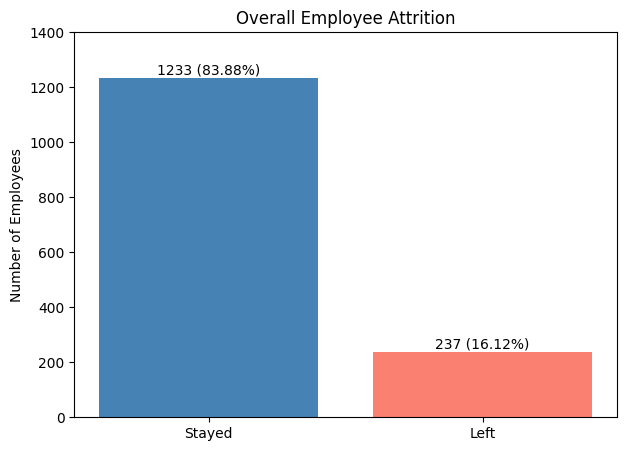

In [204]:

# Visualise overall employee attrition

import matplotlib.pyplot as plt

attrition_counts = [employees_stayed, employees_left]
labels = ["Stayed", "Left"]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    attrition_counts,
    color=["steelblue", "salmon"]
)

# Add employee counts and percentages
for bar, count in zip(bars, attrition_counts):
    percentage = count / total_employees * 100

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        f"{count} ({percentage:.2f}%)",
        ha="center"
    )

plt.title("Overall Employee Attrition")
plt.ylabel("Number of Employees")
plt.ylim(0, 1400)

plt.show()



### Key Findings

The dataset contains 1,470 employees, of whom 237 (16.12%) left the organisation, while 1,233 (83.88%) remained.

The overall attrition rate of 16.12% provides a baseline for identifying departments and employee groups with higher attrition rates.

Further analysis will examine the factors associated with employee attrition and identify opportunities for targeted retention strategies.


## 5. Departmental Attrition Analysis

### Objective

To compare employee attrition rates across departments, identify departments with higher attrition and establish a baseline for further analysis of department-specific attrition factors.

In [205]:

# Calculate employee attrition by department

department_attrition = (
    df.groupby("Department")["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
)

department_attrition["Attrition_Rate"] = (
    department_attrition["Employees_Left"] /
    department_attrition["Total_Employees"] * 100
).round(2)

department_attrition = department_attrition.sort_values(
    "Attrition_Rate", ascending=False
)

display(department_attrition)


,Total_Employees,Employees_Left,Attrition_Rate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


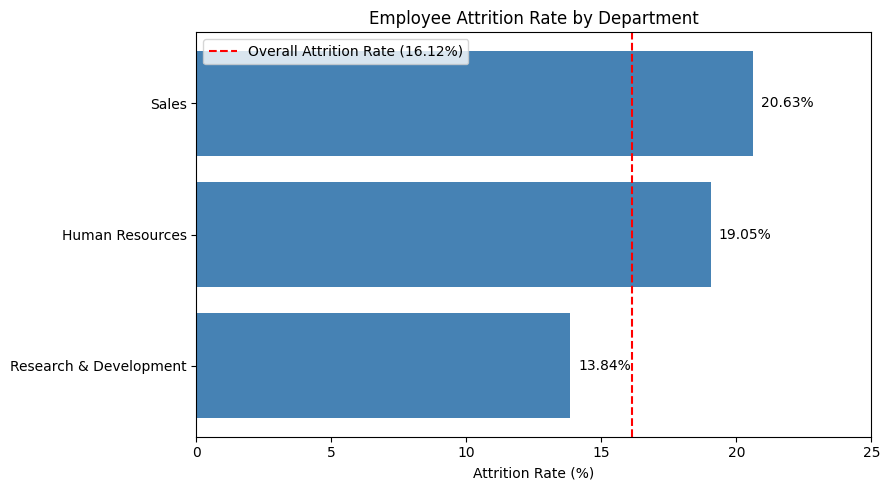

In [206]:

# Visualise attrition rates by department

plt.figure(figsize=(9, 5))

bars = plt.barh(
    department_attrition.index,
    department_attrition["Attrition_Rate"],
    color="steelblue"
)

# Add attrition rate labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center"
    )

# Overall attrition rate as benchmark
plt.axvline(
    overall_attrition_rate,
    color="red",
    linestyle="--",
    label=f"Overall Attrition Rate ({overall_attrition_rate:.2f}%)"
)

plt.title("Employee Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.xlim(0, 25)
plt.gca().invert_yaxis()
plt.legend()
plt.tight_layout()
plt.show()



### Key Findings

Sales recorded the highest attrition rate at 20.63% (92 out of 446 employees), followed by Human Resources at 19.05% (12 out of 63 employees). Both departments exceeded the overall attrition rate of 16.12%.

Research & Development recorded the lowest attrition rate at 13.84%. However, it had the highest number of employees who left (133), reflecting its larger workforce.

These findings indicate that Sales and Human Resources have higher relative attrition rates, while Research & Development contributes the largest number of employee departures.

Further analysis will examine the factors associated with attrition within each department to identify potential areas for targeted retention strategies.




## 6. Key Attrition Factors by Department

### 6.1 Department Attrition by Age

**Objective:** To examine employee attrition across different age groups within each department and identify groups with higher attrition rates.

In [207]:

# Create age groups
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 29, 39, 49, float("inf")],
    labels=["Under 30", "30-39", "40-49", "50 and above"]
)

# Calculate attrition by department and age group
age_attrition = (
    df.groupby(["Department", "AgeGroup"], observed=True)["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

age_attrition["Attrition_Rate"] = (
    age_attrition["Employees_Left"] /
    age_attrition["Total_Employees"] * 100
).round(2)

display(age_attrition)


,Department,AgeGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Under 30,12,6,50.00
1,Human Resources,30-39,26,5,19.23
2,Human Resources,40-49,17,1,5.88
3,Human Resources,50 and above,8,0,0.00
4,Research & Development,Under 30,217,55,25.35
5,Research & Development,30-39,397,49,12.34
6,Research & Development,40-49,230,16,6.96
7,Research & Development,50 and above,117,13,11.11
8,Sales,Under 30,96,30,31.25
9,Sales,30-39,201,35,17.41


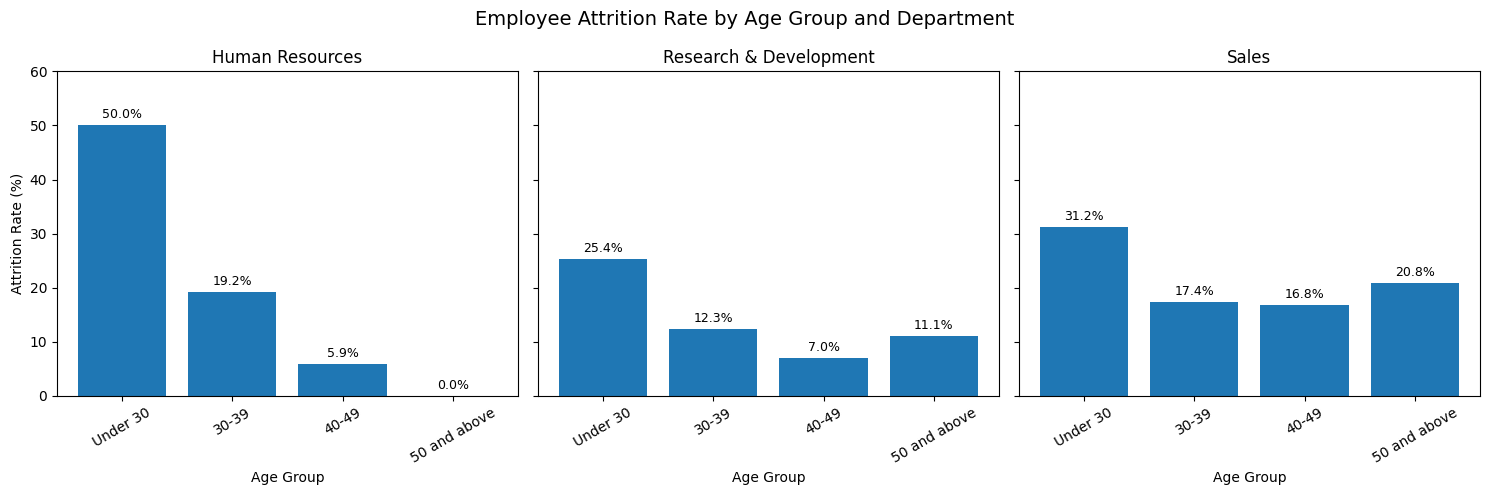

In [208]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = age_attrition[
        age_attrition["Department"] == dept
    ]

    bars = ax.bar(
        data["AgeGroup"].astype(str),
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Age Group")
    ax.set_ylim(0, 60)
    ax.tick_params(axis="x", rotation=30)

    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Age Group and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees under 30 recorded the highest attrition rate at 50.00% (6 out of 12 employees).
- **Research & Development:** Employees under 30 had the highest attrition rate at 25.35%, compared with 6.96% among employees aged 40–49.
- **Sales:** Employees under 30 recorded the highest attrition rate at 31.25%, followed by employees aged 50 and above at 20.83%.
- **Overall:** Employees under 30 consistently recorded the highest attrition rates across all three departments, suggesting that younger employees may warrant further investigation in retention planning.

*Note: The Human Resources department has a relatively small number of employees under 30 (12 employees), so its attrition rate should be interpreted cautiously.*


### 6.2 Department Attrition by Job Role

**Objective:** To compare employee attrition rates across different job roles within each department and identify roles with higher attrition rates.

In [209]:

# Calculate attrition by department and job role
role_attrition = (
    df.groupby(["Department", "JobRole"])["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

role_attrition["Attrition_Rate"] = (
    role_attrition["Employees_Left"] /
    role_attrition["Total_Employees"] * 100
).round(2)

# Sort results by department and attrition rate
role_attrition = role_attrition.sort_values(
    ["Department", "Attrition_Rate"],
    ascending=[True, False]
)

display(role_attrition)


,Department,JobRole,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Human Resources,52,12,23.08
1,Human Resources,Manager,11,0,0.00
3,Research & Development,Laboratory Technician,259,62,23.94
7,Research & Development,Research Scientist,292,47,16.10
5,Research & Development,Manufacturing Director,145,10,6.90
2,Research & Development,Healthcare Representative,131,9,6.87
4,Research & Development,Manager,54,3,5.56
6,Research & Development,Research Director,80,2,2.50
10,Sales,Sales Representative,83,33,39.76
9,Sales,Sales Executive,326,57,17.48


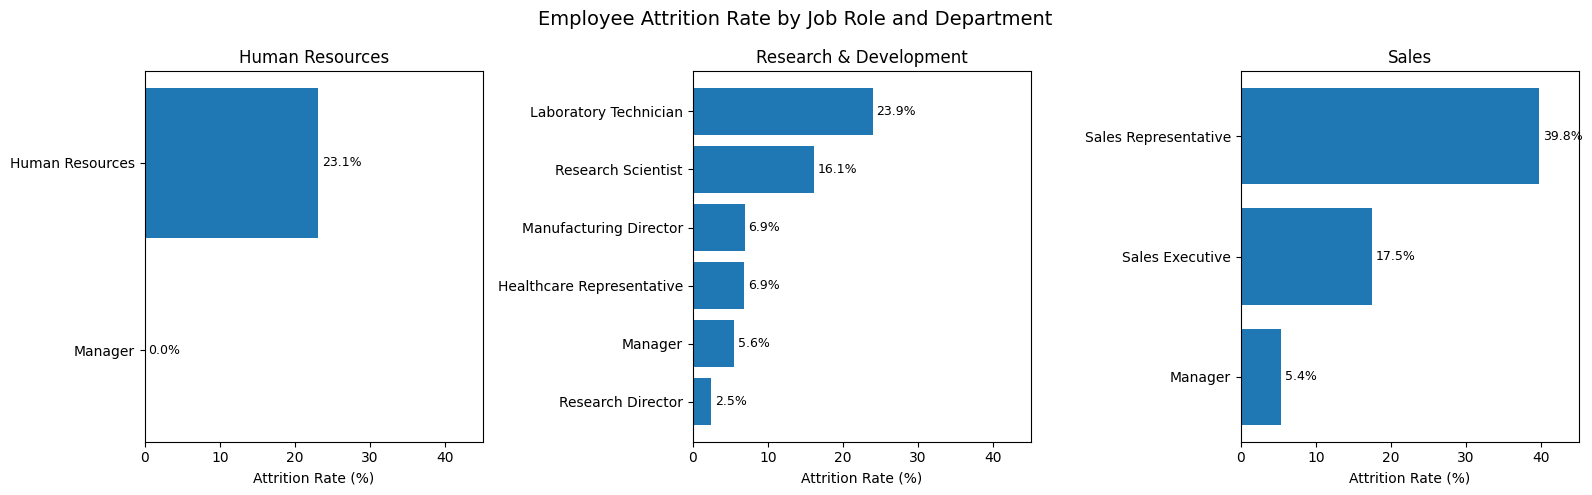

In [210]:

import matplotlib.pyplot as plt

# Create separate horizontal bar charts for each department
departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, dept in zip(axes, departments):
    data = role_attrition[
        role_attrition["Department"] == dept
    ].sort_values("Attrition_Rate")

    bars = ax.barh(
        data["JobRole"],
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Attrition Rate (%)")
    ax.set_xlim(0, 45)

    # Add percentage labels
    for bar in bars:
        width = bar.get_width()
        ax.text(
            width + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}%",
            va="center",
            fontsize=9
        )

fig.suptitle(
    "Employee Attrition Rate by Job Role and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()




**Key Findings**

- **Human Resources:** HR staff recorded an attrition rate of 23.08% (12 out of 52 employees), while no attrition was recorded among the 11 Managers.
- **Research & Development:** Laboratory Technicians had the highest attrition rate at 23.94% (62 out of 259 employees), followed by Research Scientists at 16.10%.
- **Sales:** Sales Representatives recorded the highest attrition rate at 39.76% (33 out of 83 employees), compared with 17.48% among Sales Executives.
- **Overall:** Sales Representatives and Laboratory Technicians stand out as employee groups that may warrant further investigation and targeted retention strategies.


### 6.3 Department Attrition by Monthly Income

**Objective:** To examine the relationship between monthly income and employee attrition within each department and identify income groups with higher attrition rates.

Employees are categorised into four department-specific income groups: Low, Lower-Middle, Upper-Middle and High.

In [211]:

# Create monthly income groups within each department
income_labels = ["Low", "Lower-Middle", "Upper-Middle", "High"]

df["IncomeGroup"] = (
    df.groupby("Department")["MonthlyIncome"]
    .transform(
        lambda x: pd.qcut(
            x.rank(method="first"),
            q=4,
            labels=income_labels
        )
    )
)

# Calculate attrition by department and income group
income_attrition = (
    df.groupby(["Department", "IncomeGroup"], observed=True)["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

income_attrition["Attrition_Rate"] = (
    income_attrition["Employees_Left"] /
    income_attrition["Total_Employees"] * 100
).round(2)

display(income_attrition)


,Department,IncomeGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Low,16,6,37.50
1,Human Resources,Lower-Middle,16,4,25.00
2,Human Resources,Upper-Middle,15,0,0.00
3,Human Resources,High,16,2,12.50
4,Research & Development,Low,241,65,26.97
5,Research & Development,Lower-Middle,240,36,15.00
6,Research & Development,Upper-Middle,240,17,7.08
7,Research & Development,High,240,15,6.25
8,Sales,Low,112,35,31.25
9,Sales,Lower-Middle,111,17,15.32


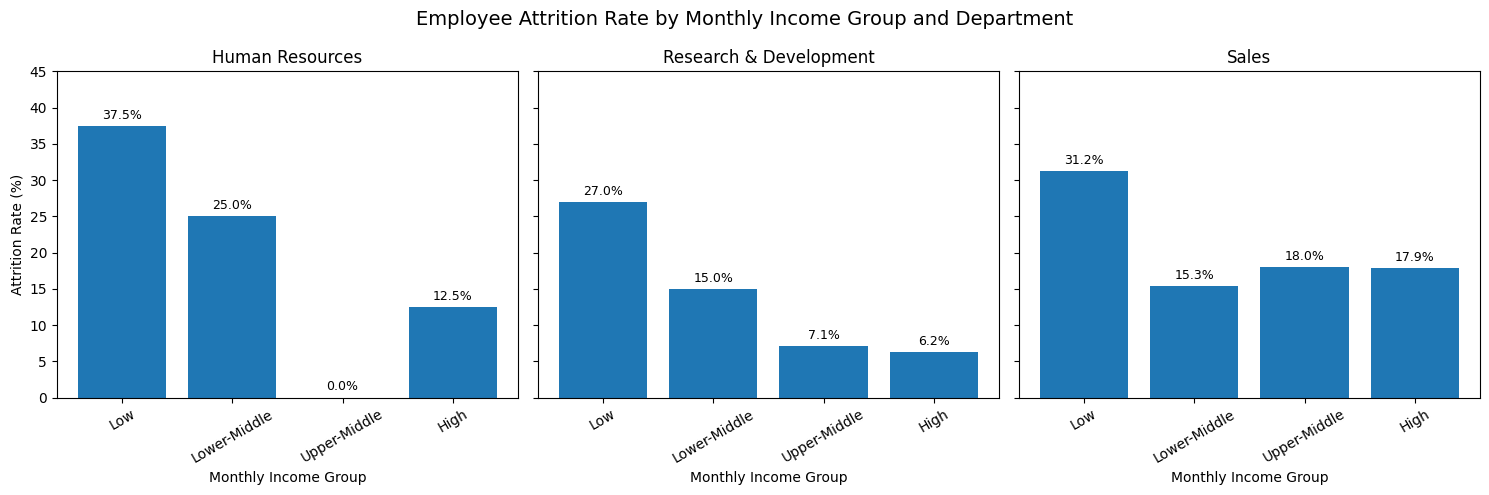

In [212]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

income_order = ["Low", "Lower-Middle", "Upper-Middle", "High"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = income_attrition[
        income_attrition["Department"] == dept
    ].set_index("IncomeGroup").reindex(income_order)

    bars = ax.bar(
        income_order,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Monthly Income Group")
    ax.set_ylim(0, 45)
    ax.tick_params(axis="x", rotation=30)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Monthly Income Group and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** The Low Income group recorded the highest attrition rate at 37.50% (6 out of 16 employees), followed by the Lower-Middle group at 25.00%.
- **Research & Development:** Attrition was highest in the Low Income group at 26.97%, declining to 6.25% in the High Income group.
- **Sales:** The Low Income group recorded the highest attrition rate at 31.25%, while the other income groups ranged from 15.32% to 18.02%.
- **Overall:** Lower-income employees consistently showed higher attrition across all three departments, suggesting that compensation-related factors warrant further investigation.

*Note: Income groups are based on department-specific quartiles. The findings show associations, not evidence that lower income causes attrition. The relatively small HR groups should also be interpreted cautiously.*


### 6.4 Department Attrition by Total Working Years

**Objective:** To examine employee attrition across different levels of total working experience within each department and identify whether less-experienced employees have higher attrition rates.

In [213]:

# Create total working experience groups
experience_labels = [
    "0-2 years",
    "3-5 years",
    "6-10 years",
    "11-20 years",
    "More than 20 years"
]

df["ExperienceGroup"] = pd.cut(
    df["TotalWorkingYears"],
    bins=[-1, 2, 5, 10, 20, float("inf")],
    labels=experience_labels
)

# Calculate attrition by department and experience group
experience_attrition = (
    df.groupby(
        ["Department", "ExperienceGroup"],
        observed=True
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

experience_attrition["Attrition_Rate"] = (
    experience_attrition["Employees_Left"] /
    experience_attrition["Total_Employees"] * 100
).round(2)

display(experience_attrition)


,Department,ExperienceGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,0-2 years,6,5,83.33
1,Human Resources,3-5 years,6,1,16.67
2,Human Resources,6-10 years,29,4,13.79
3,Human Resources,11-20 years,10,1,10.00
4,Human Resources,More than 20 years,12,1,8.33
5,Research & Development,0-2 years,83,31,37.35
6,Research & Development,3-5 years,123,21,17.07
7,Research & Development,6-10 years,396,54,13.64
8,Research & Development,11-20 years,221,19,8.60
9,Research & Development,More than 20 years,138,8,5.80


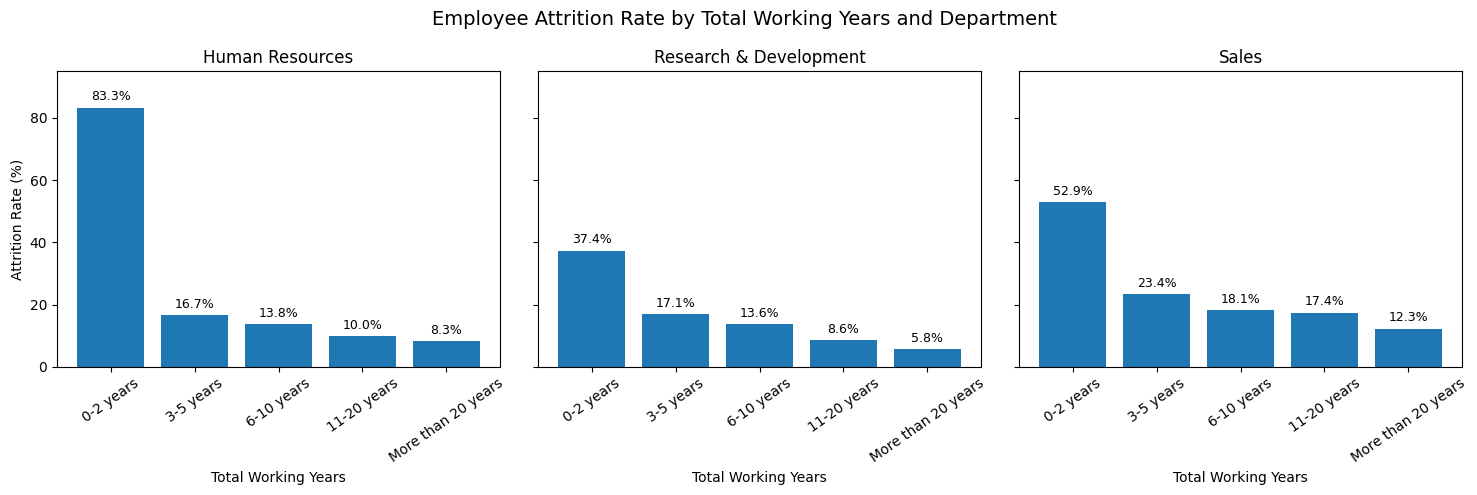

In [214]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        experience_attrition[
            experience_attrition["Department"] == dept
        ]
        .set_index("ExperienceGroup")
        .reindex(experience_labels)
    )

    bars = ax.bar(
        experience_labels,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Total Working Years")
    ax.set_ylim(0, 95)
    ax.tick_params(axis="x", rotation=35)
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Total Working Years and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees with 0–2 years of working experience recorded the highest attrition rate at 83.33% (5 out of 6 employees), compared with 8.33% among those with more than 20 years of experience.
- **Research & Development:** Attrition was highest among employees with 0–2 years of experience at 37.35%, declining to 5.80% among those with more than 20 years of experience.
- **Sales:** Employees with 0–2 years of experience recorded the highest attrition rate at 52.94%, compared with 12.28% among those with more than 20 years of experience.
- **Overall:** Employees with less working experience consistently showed higher attrition across all three departments. This suggests that early-career employees may be an important group for HR to investigate when developing retention strategies.

*Note: The HR department has only 6 employees in the 0–2 years experience group, so its high attrition rate should be interpreted cautiously. Total working experience is different from tenure with the current organisation.*


### 6.5 Department Attrition by Years Since Last Promotion

**Objective:** To examine the relationship between years since last promotion and employee attrition across departments, and identify whether longer periods without promotion are associated with higher attrition rates.

In [215]:

# Create promotion groups
promotion_labels = [
    "0 years",
    "1-2 years",
    "3-5 years",
    "More than 5 years"
]

df["PromotionGroup"] = pd.cut(
    df["YearsSinceLastPromotion"],
    bins=[-1, 0, 2, 5, float("inf")],
    labels=promotion_labels
)

# Calculate attrition by department and promotion group
promotion_attrition = (
    df.groupby(
        ["Department", "PromotionGroup"],
        observed=True
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

promotion_attrition["Attrition_Rate"] = (
    promotion_attrition["Employees_Left"] /
    promotion_attrition["Total_Employees"] * 100
).round(2)

display(promotion_attrition)


,Department,PromotionGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,0 years,24,6,25.00
1,Human Resources,1-2 years,25,5,20.00
2,Human Resources,3-5 years,9,1,11.11
3,Human Resources,More than 5 years,5,0,0.00
4,Research & Development,0 years,379,65,17.15
5,Research & Development,1-2 years,346,42,12.14
6,Research & Development,3-5 years,102,8,7.84
7,Research & Development,More than 5 years,134,18,13.43
8,Sales,0 years,178,39,21.91
9,Sales,1-2 years,145,29,20.00


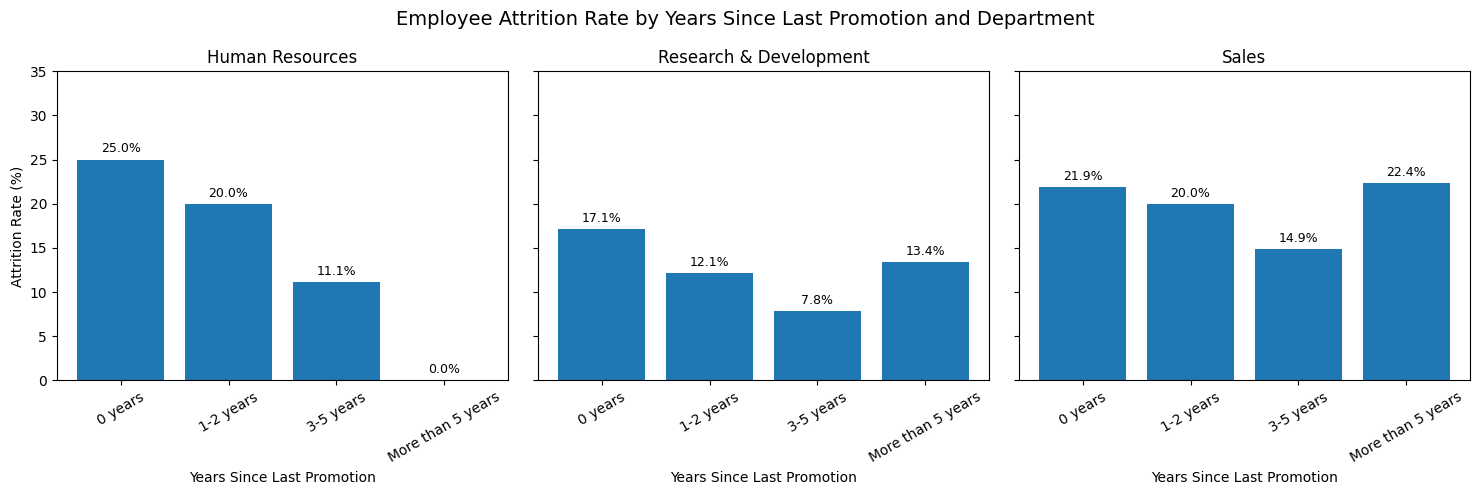

In [216]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        promotion_attrition[
            promotion_attrition["Department"] == dept
        ]
        .set_index("PromotionGroup")
        .reindex(promotion_labels)
    )

    bars = ax.bar(
        promotion_labels,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Years Since Last Promotion")
    ax.set_ylim(0, 35)
    ax.tick_params(axis="x", rotation=30)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Years Since Last Promotion and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees in the 0-year group recorded the highest attrition rate at 25.00% (6 out of 24 employees). No attrition was recorded among the 5 employees in the more-than-5-years group.
- **Research & Development:** The 0-year group had the highest attrition rate at 17.15%, followed by employees with more than 5 years since their last promotion at 13.43%.
- **Sales:** Employees with more than 5 years since their last promotion recorded the highest attrition rate at 22.37%, slightly above the 0-year group at 21.91%.
- **Overall:** There is no consistent relationship between years since last promotion and attrition across the three departments. Career progression may warrant further investigation alongside other factors such as job satisfaction and total working experience.

*Note: The 0-year category may include employees who have never been promoted. Small employee groups, particularly in Human Resources, should be interpreted cautiously.*


### 6.6 Department Attrition by Performance Rating

**Objective:** To examine the relationship between employee performance ratings and attrition across departments, and identify whether attrition rates differ between performance levels.

In [217]:

# Calculate attrition by department and performance rating
performance_attrition = (
    df.groupby(
        ["Department", "PerformanceRating"]
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

performance_attrition["Attrition_Rate"] = (
    performance_attrition["Employees_Left"] /
    performance_attrition["Total_Employees"] * 100
).round(2)

# Sort results by department and performance rating
performance_attrition = performance_attrition.sort_values(
    ["Department", "PerformanceRating"]
)

display(performance_attrition)


,Department,PerformanceRating,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,3,54,11,20.37
1,Human Resources,4,9,1,11.11
2,Research & Development,3,805,107,13.29
3,Research & Development,4,156,26,16.67
4,Sales,3,385,82,21.30
5,Sales,4,61,10,16.39


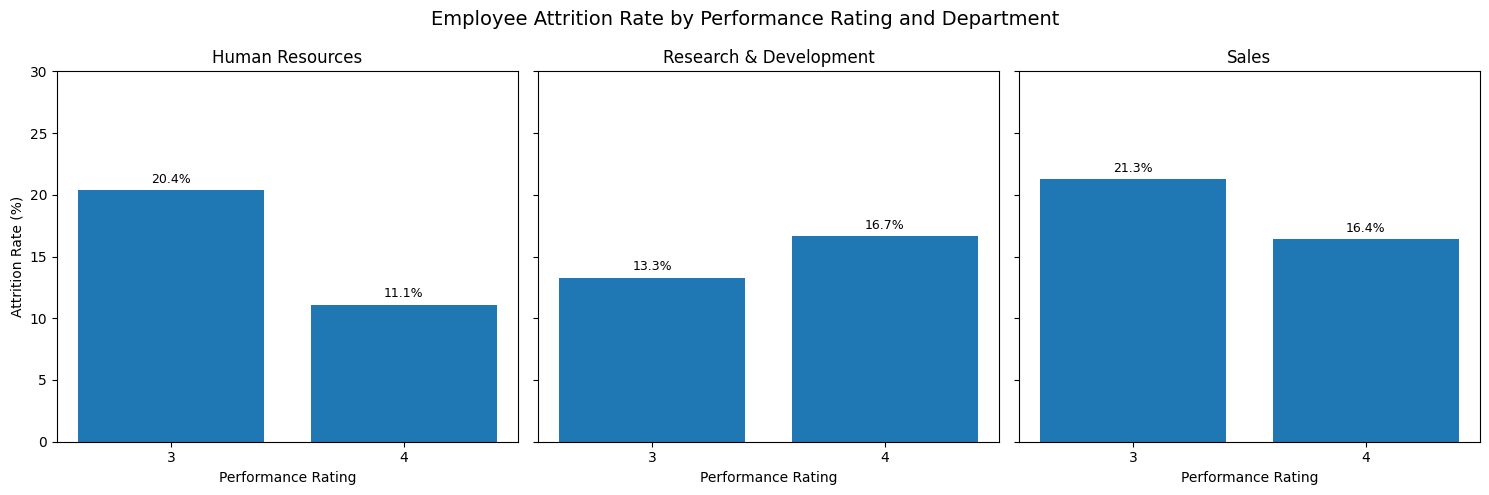

In [218]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = performance_attrition[
        performance_attrition["Department"] == dept
    ].sort_values("PerformanceRating")

    bars = ax.bar(
        data["PerformanceRating"].astype(str),
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Performance Rating")
    ax.set_ylim(0, 30)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Performance Rating and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees with Performance Rating 3 recorded a higher attrition rate (20.37%) than those with Rating 4 (11.11%).
- **Research & Development:** Employees with Rating 4 had a slightly higher attrition rate (16.67%) than those with Rating 3 (13.29%).
- **Sales:** Employees with Rating 3 recorded a higher attrition rate (21.30%) compared with those with Rating 4 (16.39%).
- **Overall:** Performance Rating does not show a consistent relationship with attrition across departments. The findings suggest that higher-rated employees are not necessarily less likely to leave.

*Note: The dataset contains only Performance Ratings 3 and 4. The small number of HR employees with Rating 4 (9 employees) should also be considered when interpreting the results.*


### 6.7 Department Attrition by Job Satisfaction

**Objective:** To examine the relationship between employee job satisfaction and attrition across departments, and identify whether employees with lower job satisfaction have higher attrition rates.

In [219]:

# Define job satisfaction levels
satisfaction_labels = {
    1: "Low",
    2: "Medium",
    3: "High",
    4: "Very High"
}

satisfaction_order = [
    "Low", "Medium", "High", "Very High"
]

# Create descriptive satisfaction categories
df["SatisfactionGroup"] = (
    df["JobSatisfaction"].map(satisfaction_labels)
)

# Calculate attrition by department and job satisfaction
satisfaction_attrition = (
    df.groupby(
        ["Department", "SatisfactionGroup"]
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

satisfaction_attrition["Attrition_Rate"] = (
    satisfaction_attrition["Employees_Left"] /
    satisfaction_attrition["Total_Employees"] * 100
).round(2)

# Arrange results in satisfaction order
satisfaction_attrition["SatisfactionGroup"] = pd.Categorical(
    satisfaction_attrition["SatisfactionGroup"],
    categories=satisfaction_order,
    ordered=True
)

satisfaction_attrition = satisfaction_attrition.sort_values(
    ["Department", "SatisfactionGroup"]
)

display(satisfaction_attrition)


,Department,SatisfactionGroup,Total_Employees,Employees_Left,Attrition_Rate
1,Human Resources,Low,11,5,45.45
2,Human Resources,Medium,20,2,10.00
0,Human Resources,High,15,3,20.00
3,Human Resources,Very High,17,2,11.76
5,Research & Development,Low,192,38,19.79
6,Research & Development,Medium,174,24,13.79
4,Research & Development,High,300,43,14.33
7,Research & Development,Very High,295,28,9.49
9,Sales,Low,86,23,26.74
10,Sales,Medium,86,20,23.26


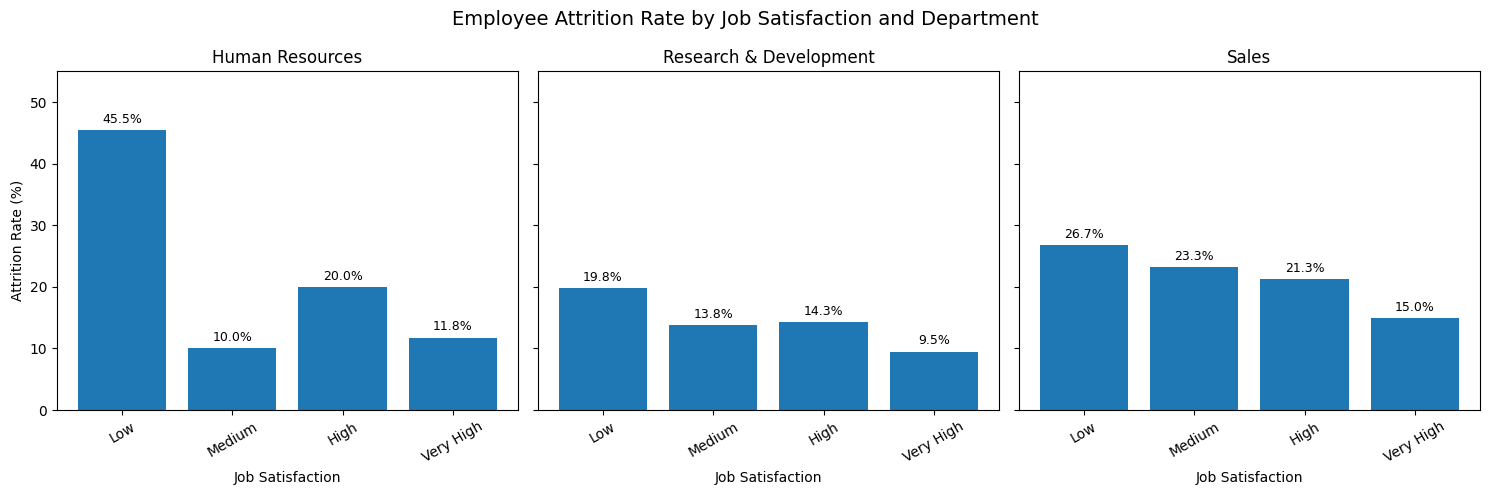

In [220]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        satisfaction_attrition[
            satisfaction_attrition["Department"] == dept
        ]
        .set_index("SatisfactionGroup")
        .reindex(satisfaction_order)
    )

    bars = ax.bar(
        satisfaction_order,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Job Satisfaction")
    ax.set_ylim(0, 55)
    ax.tick_params(axis="x", rotation=30)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Job Satisfaction and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees with Low Job Satisfaction recorded the highest attrition rate at 45.45% (5 out of 11 employees), compared with 11.76% among those with Very High Job Satisfaction.
- **Research & Development:** Attrition was highest among employees with Low Job Satisfaction at 19.79%, compared with 9.49% among those with Very High Job Satisfaction.
- **Sales:** Employees with Low Job Satisfaction recorded the highest attrition rate at 26.74%, while those with Very High Job Satisfaction had the lowest rate at 14.97%.
- **Overall:** Low Job Satisfaction was associated with higher attrition across all three departments. This suggests that employee satisfaction and engagement may be important areas for HR to investigate when developing retention strategies.

*Note: The Human Resources Low Satisfaction group contains only 11 employees, so its attrition rate should be interpreted cautiously. The relationship does not establish that low satisfaction causes attrition.*


### 6.8 Department Attrition by Work-Life Balance

**Objective:** To examine the relationship between employee work-life balance and attrition across departments, and identify whether employees reporting poorer work-life balance experience higher attrition rates.

In [221]:

# Define work-life balance levels
wlb_labels = {
    1: "Bad",
    2: "Good",
    3: "Better",
    4: "Best"
}

wlb_order = ["Bad", "Good", "Better", "Best"]

# Create descriptive work-life balance categories
df["WorkLifeBalanceGroup"] = (
    df["WorkLifeBalance"].map(wlb_labels)
)

# Calculate attrition by department and work-life balance
wlb_attrition = (
    df.groupby(
        ["Department", "WorkLifeBalanceGroup"]
    )["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

wlb_attrition["Attrition_Rate"] = (
    wlb_attrition["Employees_Left"] /
    wlb_attrition["Total_Employees"] * 100
).round(2)

# Arrange results in work-life balance order
wlb_attrition["WorkLifeBalanceGroup"] = pd.Categorical(
    wlb_attrition["WorkLifeBalanceGroup"],
    categories=wlb_order,
    ordered=True
)

wlb_attrition = wlb_attrition.sort_values(
    ["Department", "WorkLifeBalanceGroup"]
)

display(wlb_attrition)


,Department,WorkLifeBalanceGroup,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,Bad,4,0,0.00
3,Human Resources,Good,7,2,28.57
2,Human Resources,Better,42,9,21.43
1,Human Resources,Best,10,1,10.00
4,Research & Development,Bad,60,19,31.67
7,Research & Development,Good,235,32,13.62
6,Research & Development,Better,575,68,11.83
5,Research & Development,Best,91,14,15.38
8,Sales,Bad,16,6,37.50
11,Sales,Good,102,24,23.53


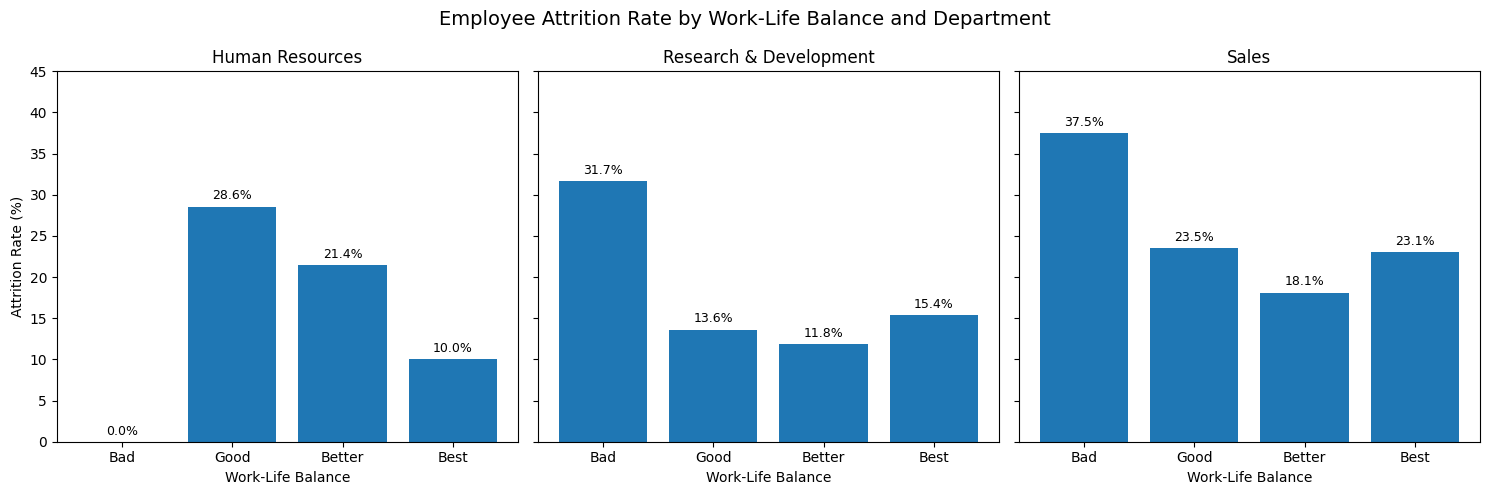

In [222]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        wlb_attrition[
            wlb_attrition["Department"] == dept
        ]
        .set_index("WorkLifeBalanceGroup")
        .reindex(wlb_order)
    )

    bars = ax.bar(
        wlb_order,
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Work-Life Balance")
    ax.set_ylim(0, 45)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Work-Life Balance and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees reporting Good Work-Life Balance recorded the highest attrition rate at 28.57% (2 out of 7 employees), while no attrition was recorded among the 4 employees reporting Bad Work-Life Balance.
- **Research & Development:** Employees reporting Bad Work-Life Balance had the highest attrition rate at 31.67% (19 out of 60 employees), compared with 11.83% among those reporting Better Work-Life Balance.
- **Sales:** Employees reporting Bad Work-Life Balance recorded the highest attrition rate at 37.50% (6 out of 16 employees), compared with 18.12% among those reporting Better Work-Life Balance.
- **Overall:** Poor Work-Life Balance was associated with higher attrition in R&D and Sales. This suggests that workload management and employee well-being may warrant further investigation as part of HR retention planning.

*Note: The Human Resources Bad Work-Life Balance group contains only 4 employees, while the Sales group contains 16 employees. These smaller groups should be interpreted cautiously. The findings show associations rather than causation.*


### 6.9 Department Attrition by Overtime

**Objective:** To examine the relationship between overtime and employee attrition across departments, and identify whether employees who work overtime experience higher attrition rates.

In [223]:

# Calculate attrition by department and overtime
overtime_attrition = (
    df.groupby(["Department", "OverTime"])["Attrition"]
    .agg(
        Total_Employees="count",
        Employees_Left=lambda x: (x == "Yes").sum()
    )
    .reset_index()
)

overtime_attrition["Attrition_Rate"] = (
    overtime_attrition["Employees_Left"] /
    overtime_attrition["Total_Employees"] * 100
).round(2)

# Arrange results by department and overtime status
overtime_attrition = overtime_attrition.sort_values(
    ["Department", "OverTime"]
)

display(overtime_attrition)


,Department,OverTime,Total_Employees,Employees_Left,Attrition_Rate
0,Human Resources,No,46,7,15.22
1,Human Resources,Yes,17,5,29.41
2,Research & Development,No,690,59,8.55
3,Research & Development,Yes,271,74,27.31
4,Sales,No,318,44,13.84
5,Sales,Yes,128,48,37.50


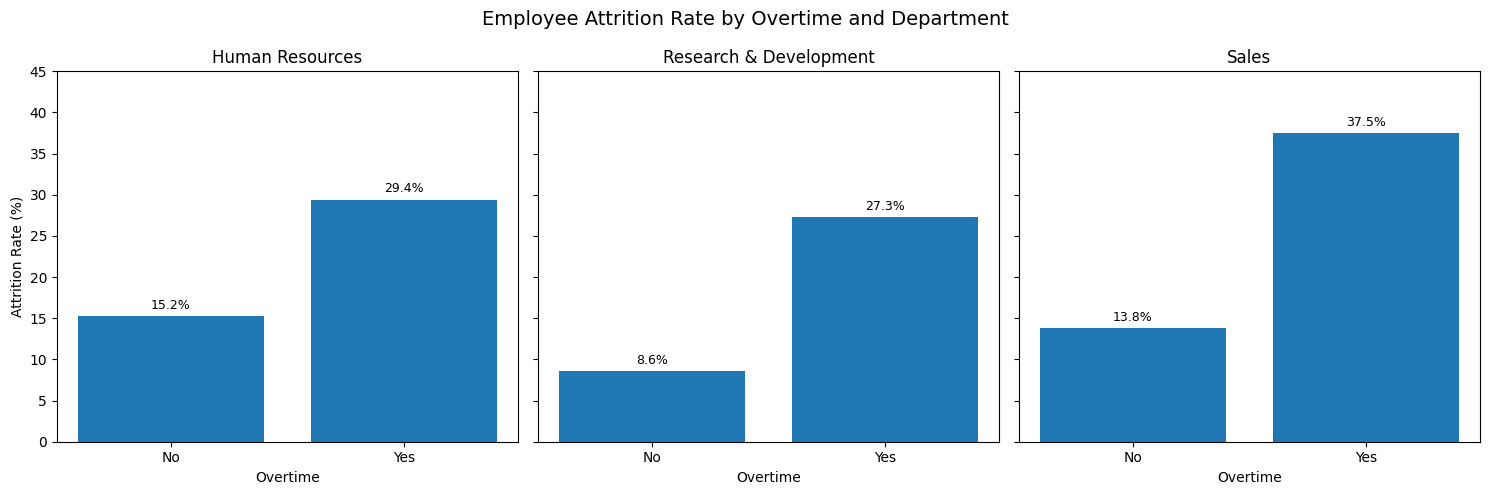

In [224]:

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for ax, dept in zip(axes, departments):
    data = (
        overtime_attrition[
            overtime_attrition["Department"] == dept
        ]
        .set_index("OverTime")
        .reindex(["No", "Yes"])
    )

    bars = ax.bar(
        ["No", "Yes"],
        data["Attrition_Rate"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Overtime")
    ax.set_ylim(0, 45)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Attrition Rate (%)")

fig.suptitle(
    "Employee Attrition Rate by Overtime and Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** Employees working overtime recorded an attrition rate of 29.41%, compared with 15.22% among those not working overtime.
- **Research & Development:** Employees working overtime had an attrition rate of 27.31%, compared with 8.55% among those not working overtime.
- **Sales:** Employees working overtime recorded the highest attrition rate at 37.50%, compared with 13.84% among those not working overtime.
- **Overall:** Overtime was consistently associated with higher attrition across all three departments, with the largest percentage-point difference observed in Sales. This suggests that workload management and overtime practices should be prioritised for further investigation when developing employee retention strategies.

*Note: These findings show an association between overtime and attrition, but do not establish that overtime causes employees to leave.*

## **Part 2 - Predictive Analystics**


## 7. Predictive Employee Attrition Modelling

### Objective

To develop and evaluate a predictive model that estimates the likelihood of employee attrition using key employee characteristics, compensation, experience, performance, satisfaction and overtime information.

The predictive analysis aims to:

1. Identify employees who may be at higher risk of attrition.
2. Evaluate how accurately the model predicts employee attrition.
3. Identify factors associated with higher predicted attrition risk.
4. Support proactive employee retention strategies and workforce planning.

### Selected Predictive Factors

The model will initially use the following nine factors:

1. Age
2. Job Role
3. Monthly Income
4. Total Working Years
5. Years Since Last Promotion
6. Performance Rating
7. Job Satisfaction
8. Work-Life Balance
9. Overtime

### Modelling Approach

We will prepare the dataset, split it into training and testing sets, develop suitable classification models, and evaluate their predictive performance.

The model will generate attrition probabilities that can subsequently support the Employee Attrition Risk Study in Section 8.

*Note: The IBM HR dataset is a sample dataset. Predictions demonstrate an analytical approach and should not be treated as validated predictions for actual employees.*

In [225]:

# Section 7.1 - Select variables for predictive modelling

predictor_columns = [
    "Age",
    "JobRole",
    "MonthlyIncome",
    "TotalWorkingYears",
    "YearsSinceLastPromotion",
    "PerformanceRating",
    "JobSatisfaction",
    "WorkLifeBalance",
    "OverTime"
]

target_column = "Attrition"

# Create a separate dataset for predictive modelling
model_df = df[predictor_columns + [target_column]].copy()

print("Modelling dataset shape:", model_df.shape)

print("\nMissing values:")
display(model_df.isnull().sum().to_frame("Missing_Values"))

print("\nAttrition distribution:")
display(model_df["Attrition"].value_counts().to_frame("Employees"))

print("\nSample records:")
display(model_df.head())


Modelling dataset shape: (1470, 10)

Missing values:


,Missing_Values
Age,0
JobRole,0
MonthlyIncome,0
TotalWorkingYears,0
YearsSinceLastPromotion,0
PerformanceRating,0
JobSatisfaction,0
WorkLifeBalance,0
OverTime,0
Attrition,0



Attrition distribution:


,Employees
Attrition,
No,1233
Yes,237



Sample records:


,Age,JobRole,MonthlyIncome,TotalWorkingYears,YearsSinceLastPromotion,PerformanceRating,JobSatisfaction,WorkLifeBalance,OverTime,Attrition
0,41.0,Sales Executive,5993,8,0,3,4,1,Yes,Yes
1,49.0,Research Scientist,5130,10,1,4,2,3,No,No
2,37.0,Laboratory Technician,2090,7,0,3,3,3,Yes,Yes
3,33.0,Research Scientist,2909,8,3,3,3,3,Yes,No
4,27.0,Laboratory Technician,3468,6,2,3,2,3,No,No



### 7.1 Data Preparation and Train-Test Split

The dataset is divided into training (80%) and testing (20%) sets using stratified sampling to maintain the proportion of employees who left and stayed.

The training dataset will be used to develop the predictive model, while the testing dataset will be used to evaluate its performance on unseen records.

Missing-value imputation and categorical encoding will be fitted using training data only to reduce the risk of data leakage.

In [226]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Section 7.1 - Prepare data and split into training and testing sets

# Separate predictors and target
X = model_df[predictor_columns].copy()
y = model_df["Attrition"].map({"No": 0, "Yes": 1})

# Load original employee data to restore missing ages
employees_original = pd.read_csv(
    "https://raw.githubusercontent.com/junelwc6-source/"
    "IBM-HR-Attrition-Analytics/main/Employees.csv"
)

# Check that employee counts match
assert len(employees_original) == len(X), "Employee row counts differ."

# Check that EmployeeNumber is unique in both datasets
assert df["EmployeeNumber"].is_unique, "Duplicate employees in merged data."
assert employees_original["EmployeeNumber"].is_unique, "Duplicate employees in source data."

# Check that every employee can be matched
assert df["EmployeeNumber"].isin(
    employees_original["EmployeeNumber"]
).all(), "Some employees could not be matched."

# Restore original ages by matching EmployeeNumber
age_lookup = employees_original.set_index("EmployeeNumber")["Age"]

X["Age"] = df["EmployeeNumber"].map(age_lookup).to_numpy()

# Split data into 80% training and 20% testing
# Stratify to maintain the proportion of employees who left
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display results
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining attrition distribution:")
display(y_train.value_counts())

print("\nTesting attrition distribution:")
display(y_test.value_counts())

print("\nMissing ages in training:", X_train["Age"].isna().sum())
print("Missing ages in testing:", X_test["Age"].isna().sum())


Training records: 1176
Testing records: 294

Training attrition distribution:


,count
Attrition,
0,986
1,190



Testing attrition distribution:


,count
Attrition,
0,247
1,47



Missing ages in training: 4
Missing ages in testing: 1



### 7.2 Data Preprocessing

The selected predictive variables consist of numerical and categorical data.

Numerical variables will be processed using median imputation for missing values and standard scaling.

Categorical variables will be converted into numerical features using one-hot encoding.

All preprocessing steps will be fitted on the training dataset only and subsequently applied to the testing dataset to prevent data leakage.

In [227]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define numerical and categorical variables
numerical_features = [
    "Age",
    "MonthlyIncome",
    "TotalWorkingYears",
    "YearsSinceLastPromotion",
    "PerformanceRating",
    "JobSatisfaction",
    "WorkLifeBalance"
]

categorical_features = [
    "JobRole",
    "OverTime"
]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))


Preprocessing pipeline created successfully.
Numerical features: 7
Categorical features: 2



### 7.3 Logistic Regression Model

Logistic Regression is used as the first predictive model to estimate the probability of employee attrition.

The model combines the preprocessing pipeline with Logistic Regression to ensure that missing-value treatment, feature scaling and categorical encoding are learned from the training dataset only.

Class weighting is applied to account for the imbalance between employees who stayed and those who left.

The model will subsequently be evaluated using the testing dataset.

In [228]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using training data only
logistic_model.fit(X_train, y_train)

# Generate predictions on unseen testing data
y_pred_logistic = logistic_model.predict(X_test)

# Generate predicted attrition probabilities
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression model trained successfully.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Predictions generated:", len(y_pred_logistic))


Logistic Regression model trained successfully.
Training records: 1176
Testing records: 294
Predictions generated: 294



### 7.4 Logistic Regression Model Evaluation

The Logistic Regression model is evaluated using the testing dataset, which was not used during model training.

The evaluation includes Accuracy, Precision, Recall, F1-Score and ROC-AUC.

Particular attention is given to Recall, as the project aims to identify employees who may be at risk of attrition. Precision is also considered to assess how many predicted attrition cases are correctly identified.

In [229]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# Calculate Logistic Regression performance metrics
logistic_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_logistic, zero_division=0),
        recall_score(y_test, y_pred_logistic, zero_division=0),
        f1_score(y_test, y_pred_logistic, zero_division=0),
        roc_auc_score(y_test, y_prob_logistic)
    ]
})

logistic_results["Score"] = logistic_results["Score"].round(3)

print("Logistic Regression Performance:")
display(logistic_results)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_logistic,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Logistic Regression Performance:


,Metric,Score
0,Accuracy,0.704
1,Precision,0.304
2,Recall,0.660
3,F1-Score,0.416
4,ROC-AUC,0.733



Confusion Matrix:
[[176  71]
 [ 16  31]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.92      0.71      0.80       247
        Left       0.30      0.66      0.42        47

    accuracy                           0.70       294
   macro avg       0.61      0.69      0.61       294
weighted avg       0.82      0.70      0.74       294




**Key Findings**

- The Logistic Regression model achieved an accuracy of 70.4% and ROC-AUC of 0.733, indicating moderate predictive performance.
- The model correctly identified 31 of the 47 employees who left, achieving a recall of 66.0%.
- However, precision was relatively low at 30.4%, with 71 employees incorrectly predicted to leave.
- The results suggest that Logistic Regression can help identify potential attrition risk, but further model comparison and improvement are needed before using the predictions to support HR retention strategies.

**Conclusion:** Logistic Regression provides a useful baseline model for employee attrition prediction. A Random Forest model will be developed next to compare predictive performance.


### 7.5 Random Forest Model

Random Forest is developed as a second classification model to predict employee attrition.

Unlike Logistic Regression, Random Forest can capture more complex and non-linear relationships between employee characteristics and attrition.

The model uses the same nine predictive factors and the same training and testing datasets to allow a fair comparison with Logistic Regression.

Class weighting is applied to address the imbalance between employees who stayed and those who left.

In [230]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Section 7.5 - Random Forest Model

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model using training data only
random_forest_model.fit(X_train, y_train)

# Generate predictions on unseen testing data
y_pred_rf = random_forest_model.predict(X_test)

# Generate predicted attrition probabilities
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Predictions generated:", len(y_pred_rf))


Random Forest model trained successfully.
Training records: 1176
Testing records: 294
Predictions generated: 294



### 7.6 Random Forest Model Evaluation

The Random Forest model is evaluated using the same testing dataset and performance metrics as Logistic Regression.

Accuracy, Precision, Recall, F1-Score and ROC-AUC are calculated to assess the model's ability to predict employee attrition.

The results will be compared with Logistic Regression to determine which model provides a better balance between identifying employees who leave and minimising false alerts.

In [231]:

# Section 7.6 - Random Forest Model Evaluation

# Calculate performance metrics
rf_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

rf_results["Score"] = rf_results["Score"].round(3)

print("Random Forest Performance:")
display(rf_results)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Random Forest Performance:


,Metric,Score
0,Accuracy,0.823
1,Precision,0.451
2,Recall,0.489
3,F1-Score,0.469
4,ROC-AUC,0.753



Confusion Matrix:
[[219  28]
 [ 24  23]]

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.89      0.89       247
        Left       0.45      0.49      0.47        47

    accuracy                           0.82       294
   macro avg       0.68      0.69      0.68       294
weighted avg       0.83      0.82      0.83       294




### 7.7 Model Performance Comparison

The performance of Logistic Regression and Random Forest was compared using the same testing dataset.

**Key Findings**

- Random Forest achieved higher accuracy (82.3%) than Logistic Regression (70.4%).
- Random Forest also achieved higher precision (45.1% vs 30.4%) and F1-Score (46.9% vs 41.6%).
- Logistic Regression achieved higher recall (66.0% vs 48.9%), identifying more employees who actually left.
- Random Forest achieved a slightly higher ROC-AUC (0.753 vs 0.733), indicating marginally better discrimination between employees who left and stayed.
- Random Forest generated fewer false positives (28 vs 71), but missed more employees who left (24 vs 16).

**Conclusion**

Random Forest demonstrated better overall classification performance at the default decision threshold, while Logistic Regression identified a higher proportion of employees who left.

Further evaluation and model improvement are required before selecting the final predictive model for employee attrition risk analysis.


### 7.8 Model Improvement — Decision Threshold Analysis

The default classification threshold of 0.50 may not provide the best balance between identifying employees who leave and minimising false alerts.

Different decision thresholds will be evaluated using cross-validation on the training dataset.

The analysis will compare Precision, Recall and F1-Score at different thresholds to identify a suitable balance for proactive employee retention planning.

The testing dataset will remain separate for final model evaluation.

In [232]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Use stratified 5-fold cross-validation on training data
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Generate out-of-fold probabilities for Random Forest
rf_cv_prob = cross_val_predict(
    random_forest_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluate different probability thresholds
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

threshold_results = []

for threshold in thresholds:
    predictions = (rf_cv_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_train, predictions, zero_division=0
        ),
        "Employees_Flagged": int(predictions.sum())
    })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results.round(3)
)


,Threshold,Precision,Recall,F1-Score,Employees_Flagged
0,0.20,0.194,0.895,0.319,875
1,0.25,0.224,0.837,0.353,711
2,0.30,0.267,0.774,0.397,550
3,0.35,0.319,0.700,0.438,417
4,0.40,0.361,0.642,0.462,338
5,0.45,0.398,0.558,0.465,266
6,0.50,0.475,0.505,0.490,202
7,0.55,0.537,0.458,0.494,162
8,0.60,0.581,0.395,0.470,129


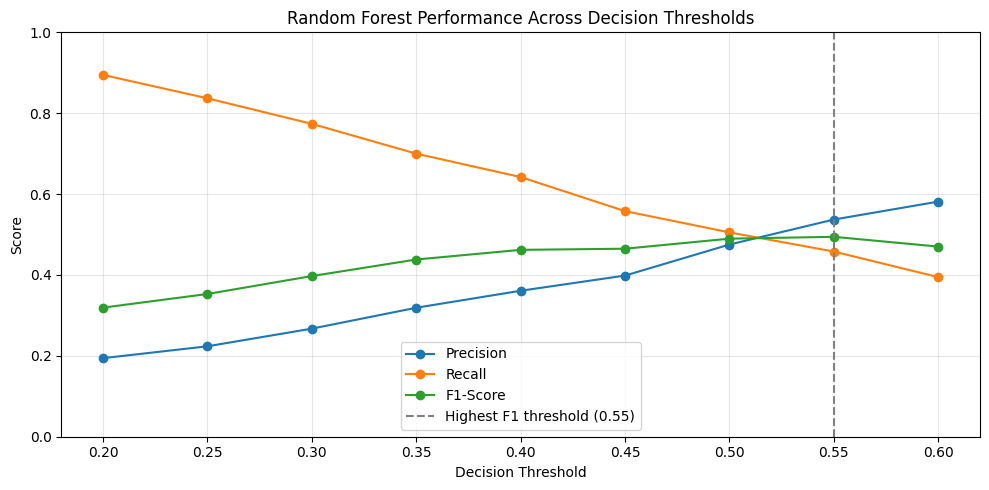

In [233]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    x=0.55,
    linestyle="--",
    color="gray",
    label="Highest F1 threshold (0.55)"
)

plt.title("Random Forest Performance Across Decision Thresholds")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Key Findings**

- Increasing the decision threshold improved precision but reduced recall, demonstrating a trade-off between reducing false alerts and identifying employees who leave.
- At the default threshold of 0.50, Random Forest achieved an F1-Score of 0.490 and recall of 50.5% during cross-validation.
- The highest F1-Score among the tested thresholds was 0.494 at a threshold of 0.55, with precision of 53.7% and recall of 45.8%.
- At a lower threshold of 0.40, recall increased to 64.2%, but precision decreased to 36.1%.
- The results suggest that threshold selection should consider HR's retention objectives and follow-up capacity, rather than relying solely on the highest F1-Score.

**Conclusion**

The 0.55 threshold is retained as a candidate based on F1-Score, while 0.40 remains an alternative for identifying a higher proportion of employees who leave.

The final threshold has not yet been selected. Further evaluation, including probability calibration, is required before developing employee attrition risk categories.


### 7.9 Probability Calibration

Probability calibration is used to assess whether the predicted attrition probabilities correspond to observed employee attrition rates.

A well-calibrated model produces probabilities that closely reflect actual outcomes across groups of employees.

As the project aims to classify employees into Low, Medium and High Attrition Risk categories, reliable probability estimates are important.

The Random Forest model will be calibrated using cross-validation on the training dataset. The testing dataset will remain separate for final evaluation.

In [234]:

from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

# Section 7.9 - Random Forest Probability Calibration

# Set up stratified cross-validation
calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create a calibrated Random Forest model
calibrated_rf_model = CalibratedClassifierCV(
    estimator=clone(random_forest_model),
    method="sigmoid",
    cv=calibration_cv
)

# Fit calibration using training data only
calibrated_rf_model.fit(X_train, y_train)

# Generate calibrated probabilities on testing data
y_prob_rf_calibrated = calibrated_rf_model.predict_proba(
    X_test
)[:, 1]

print("Random Forest probability calibration completed.")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(
    "Calibrated probabilities generated:",
    len(y_prob_rf_calibrated)
)


Random Forest probability calibration completed.
Training records: 1176
Testing records: 294
Calibrated probabilities generated: 294


Probability Calibration Comparison:


,Model,Brier_Score,ROC_AUC
0,Original Random Forest,0.151,0.753
1,Calibrated Random Forest,0.118,0.761


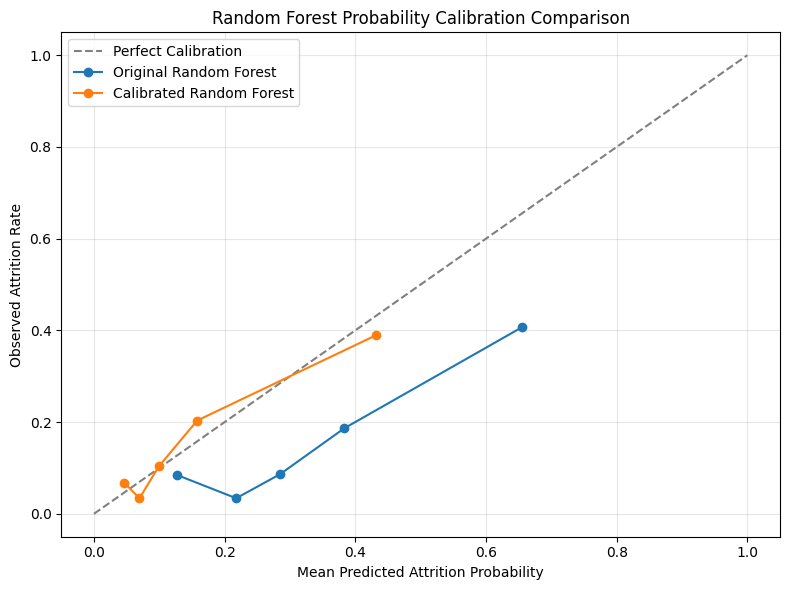

In [235]:

from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import pandas as pd

# Compare original and calibrated Random Forest
calibration_results = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Calibrated Random Forest"
    ],
    "Brier_Score": [
        brier_score_loss(y_test, y_prob_rf),
        brier_score_loss(y_test, y_prob_rf_calibrated)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_rf_calibrated)
    ]
})

print("Probability Calibration Comparison:")
display(calibration_results.round(3))

# Calculate calibration curves
original_fraction, original_mean = calibration_curve(
    y_test,
    y_prob_rf,
    n_bins=5,
    strategy="quantile"
)

calibrated_fraction, calibrated_mean = calibration_curve(
    y_test,
    y_prob_rf_calibrated,
    n_bins=5,
    strategy="quantile"
)

# Plot calibration curves
plt.figure(figsize=(8, 6))

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect Calibration"
)

plt.plot(
    original_mean,
    original_fraction,
    marker="o",
    label="Original Random Forest"
)

plt.plot(
    calibrated_mean,
    calibrated_fraction,
    marker="o",
    label="Calibrated Random Forest"
)

plt.title("Random Forest Probability Calibration Comparison")
plt.xlabel("Mean Predicted Attrition Probability")
plt.ylabel("Observed Attrition Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Key Findings**

- Probability calibration improved the Random Forest model's Brier Score from 0.151 to 0.118, indicating more reliable predicted attrition probabilities.
- ROC-AUC increased slightly from 0.753 to 0.761, suggesting a marginal improvement in the model's ability to distinguish employees who left from those who stayed.
- The calibrated model's probability curve was generally closer to the ideal calibration line, showing better alignment between predicted probabilities and observed attrition rates.
- The calibrated Random Forest model therefore provides a stronger basis for estimating employee attrition risk than the original Random Forest model.
- However, the results should be interpreted cautiously because the testing dataset contains only 47 employees who left.

**Conclusion**

The calibrated Random Forest model is selected as the preferred candidate for the Employee Attrition Risk Study, subject to final evaluation and appropriate risk-category thresholds.

The predicted probabilities will be used to examine employee groups with different levels of attrition risk and support the development of targeted HR retention recommendations.


### 7.10 Predictive Factor Importance

Permutation Importance is used to identify which employee characteristics contribute most to the calibrated Random Forest model's predictive performance.

The analysis measures how much the model's ROC-AUC decreases when each predictive factor is randomly shuffled.

A larger decrease indicates that the model relies more heavily on that factor to distinguish employees who leave from those who stay.

These results represent predictive associations and do not establish that the factors cause employee attrition.

Predictive Factor Importance:


,Factor,Importance,Std_Dev
0,OverTime,0.1569,0.0161
1,JobSatisfaction,0.0344,0.0082
2,MonthlyIncome,0.0165,0.0122
3,Age,0.0103,0.0101
4,WorkLifeBalance,0.0084,0.0053
5,YearsSinceLastPromotion,0.0062,0.0059
6,PerformanceRating,-0.0001,0.0011
7,JobRole,-0.0050,0.0130
8,TotalWorkingYears,-0.0113,0.0144


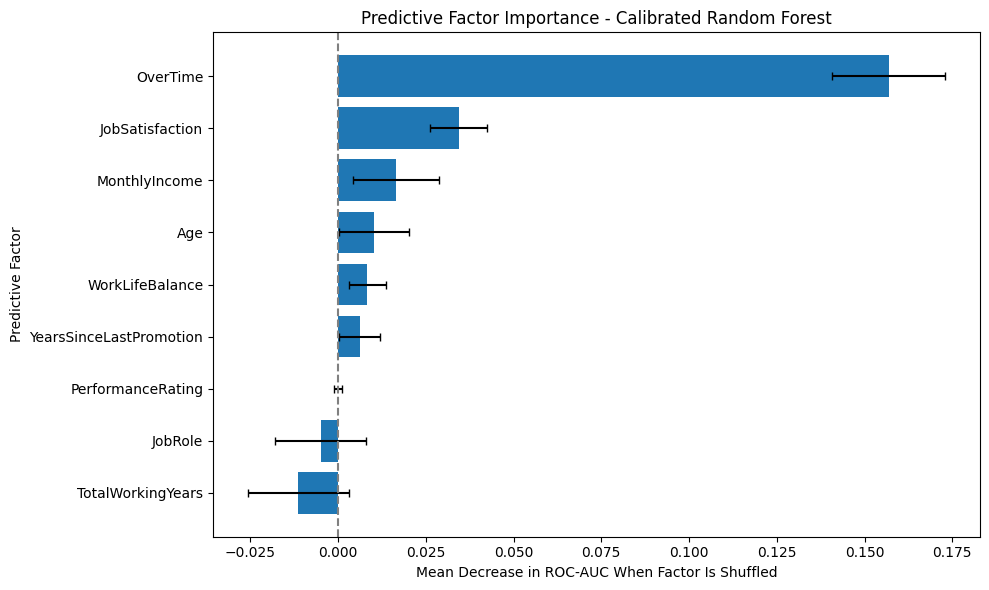

In [236]:

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Section 7.10 - Predictive Factor Importance

# Calculate permutation importance using the calibrated model
importance = permutation_importance(
    calibrated_rf_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create results table
importance_df = pd.DataFrame({
    "Factor": X_test.columns,
    "Importance": importance.importances_mean,
    "Std_Dev": importance.importances_std
})

# Sort factors from highest to lowest importance
importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

print("Predictive Factor Importance:")
display(importance_df.round(4))

# Visualise factor importance
plot_df = importance_df.sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_df["Factor"],
    plot_df["Importance"],
    xerr=plot_df["Std_Dev"],
    capsize=3
)

plt.axvline(0, color="gray", linestyle="--")

plt.title("Predictive Factor Importance - Calibrated Random Forest")
plt.xlabel("Mean Decrease in ROC-AUC When Factor Is Shuffled")
plt.ylabel("Predictive Factor")

plt.tight_layout()
plt.show()



**Key Findings**

- **Overtime** was the strongest predictive factor, with a permutation importance score of 0.1569. This is consistent with the descriptive analysis, which showed higher attrition rates among employees working overtime across all three departments.
- **Job Satisfaction** ranked second (0.0344), suggesting that employee satisfaction provides additional information for predicting attrition.
- **Monthly Income** (0.0165) and **Age** (0.0103) showed smaller positive contributions to predictive performance.
- **Work-Life Balance** and **Years Since Last Promotion** contributed limited additional predictive information.
- **Performance Rating, Job Role and Total Working Years** showed importance scores near or below zero, indicating limited additional predictive value in this model.

**Conclusion**

Overtime and Job Satisfaction emerged as the leading predictive factors in the calibrated Random Forest model.

These findings suggest that workload management and employee satisfaction are useful areas for HR to investigate when developing retention strategies.

However, predictive importance does not establish causation, and the findings should be interpreted cautiously given the relatively small testing dataset.


## 8. Employee Attrition Risk Study

### Objective

To apply the calibrated Random Forest model to examine predicted employee attrition risk and identify employee groups that may benefit from proactive retention support.

The analysis aims to:

1. Classify employees into Low, Medium and High predicted attrition risk categories.
2. Compare predicted attrition risk across Human Resources, Research & Development and Sales.
3. Identify common characteristics among employees with higher predicted attrition risk.
4. Support the development of targeted HR retention strategies and proactive workforce planning.

### Analytical Approach

The calibrated Random Forest model developed in Section 7 will be used to estimate employee attrition probabilities.

The distribution of predicted probabilities will first be examined before defining appropriate risk categories.

Departmental analysis will then be conducted to identify differences in predicted attrition risk across employee groups.

**Important:** The analysis uses a synthetic HR dataset. Predicted risk categories are illustrative and should not be used to make actual employment decisions without further validation.

Predicted Attrition Probability Summary:


,Probability
count,294.000
mean,0.161
std,0.160
min,0.031
25%,0.065
50%,0.099
75%,0.173
max,0.777


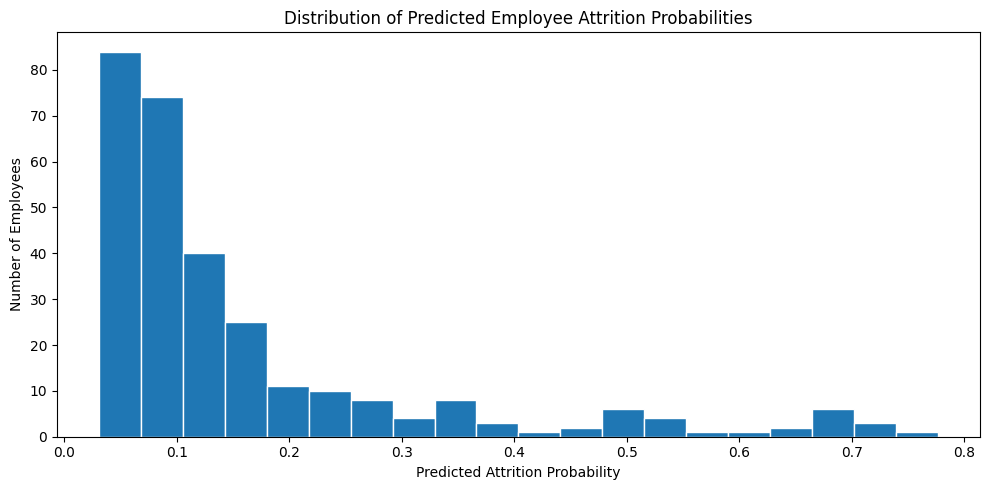

In [237]:

# Section 8.1 - Examine Predicted Attrition Probabilities

import pandas as pd
import matplotlib.pyplot as plt

# Create a test dataset containing calibrated predictions
risk_df = X_test.copy()

risk_df["Actual_Attrition"] = y_test
risk_df["Predicted_Probability"] = y_prob_rf_calibrated

# Restore department information using original test indices
risk_df["Department"] = df.loc[X_test.index, "Department"]

# Display probability summary
print("Predicted Attrition Probability Summary:")
display(
    risk_df["Predicted_Probability"]
    .describe()
    .round(3)
    .to_frame("Probability")
)

# Visualise probability distribution
plt.figure(figsize=(10, 5))

plt.hist(
    risk_df["Predicted_Probability"],
    bins=20,
    edgecolor="white"
)

plt.title("Distribution of Predicted Employee Attrition Probabilities")
plt.xlabel("Predicted Attrition Probability")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()



### 8.2 Defining Employee Attrition Risk Categories

Employees will be classified into Low, Medium and High predicted attrition risk groups using probabilities generated by the calibrated Random Forest model.

Risk boundaries will be established using out-of-fold predictions from the training dataset to avoid selecting thresholds based on the testing dataset.

The risk groups will subsequently be evaluated against actual attrition outcomes to determine whether higher predicted risk corresponds to higher observed attrition.

These categories are intended for exploratory HR workforce planning and do not represent validated thresholds for actual employment decisions.

In [238]:

from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import pandas as pd

# Generate out-of-fold calibrated probabilities
# using training data only
train_risk_prob = cross_val_predict(
    clone(calibrated_rf_model),
    X_train,
    y_train,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Summarise training-data probabilities
train_risk_summary = pd.Series(
    train_risk_prob,
    name="Predicted_Probability"
)

print("Training Data - Predicted Attrition Probability Summary:")
display(train_risk_summary.describe().round(3))

print("\nSelected Probability Percentiles:")
display(
    train_risk_summary.quantile(
        [0.25, 0.50, 0.75, 0.80, 0.90]
    ).round(3).to_frame("Probability")
)


Training Data - Predicted Attrition Probability Summary:


,Predicted_Probability
count,1176.000
mean,0.163
std,0.147
min,0.026
25%,0.070
50%,0.106
75%,0.193
max,0.759



Selected Probability Percentiles:


,Probability
0.25,0.070
0.50,0.106
0.75,0.193
0.80,0.227
0.90,0.376


In [239]:

# Section 8.2 - Define Employee Attrition Risk Categories

import numpy as np
import pandas as pd

# Determine thresholds from training data only
low_cutoff = np.quantile(train_risk_prob, 0.50)
high_cutoff = np.quantile(train_risk_prob, 0.80)

print(f"Low/Medium cutoff: {low_cutoff:.3f}")
print(f"Medium/High cutoff: {high_cutoff:.3f}")

# Classify employees in the held-out test dataset
risk_df["Risk_Category"] = pd.cut(
    risk_df["Predicted_Probability"],
    bins=[-np.inf, low_cutoff, high_cutoff, np.inf],
    labels=["Low Risk", "Medium Risk", "High Risk"],
    right=False
)

# Summarise risk categories
risk_summary = (
    risk_df.groupby(
        "Risk_Category",
        observed=True
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum"),
        Average_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .reset_index()
)

risk_summary["Observed_Attrition_Rate"] = (
    risk_summary["Employees_Left"] /
    risk_summary["Total_Employees"] * 100
).round(2)

risk_summary["Average_Predicted_Risk"] = (
    risk_summary["Average_Predicted_Risk"] * 100
).round(2)

print("\nEmployee Attrition Risk Classification:")
display(risk_summary)


Low/Medium cutoff: 0.106
Medium/High cutoff: 0.227

Employee Attrition Risk Classification:


,Risk_Category,Total_Employees,Employees_Left,Average_Predicted_Risk,Observed_Attrition_Rate
0,Low Risk,159,12,6.70,7.55
1,Medium Risk,77,12,14.92,15.58
2,High Risk,58,23,43.59,39.66



**Key Findings**

- Employees were classified into Low, Medium and High Risk categories using probability thresholds derived from the training dataset.
- The Low Risk group comprised 159 employees, with an observed attrition rate of 7.55%.
- The Medium Risk group comprised 77 employees, with an observed attrition rate of 15.58%.
- The High Risk group comprised 58 employees, with an observed attrition rate of 39.66%.
- The observed attrition rate increased consistently across the three risk categories, suggesting that the calibrated Random Forest model can distinguish employee groups with different levels of attrition risk.
- Average predicted probabilities were reasonably close to observed attrition rates across the groups.

**Conclusion**

The calibrated Random Forest model demonstrated useful risk differentiation within the held-out testing dataset.

The High Risk group showed a substantially higher observed attrition rate than the Low Risk group, supporting further analysis of high-risk employee characteristics and departmental patterns.

However, the findings remain exploratory and require further validation before application to actual HR workforce decisions.


### 8.3 Departmental Attrition Risk Analysis

**Objective:** To examine the distribution of predicted employee attrition risk across Human Resources, Research & Development and Sales.

The analysis aims to:

1. Identify the number and proportion of employees classified as Low, Medium and High Risk within each department.
2. Compare the concentration of High Risk employees across departments.
3. Identify departments that may require closer attention in workforce planning and employee retention efforts.

The analysis uses the held-out testing dataset of 294 employees and the calibrated Random Forest model developed in Section 7.

Risk categories are based on probability thresholds established using the training dataset.

In [240]:

# Section 8.3 - Departmental Attrition Risk Analysis

import pandas as pd

# Calculate employee counts by department and risk category
department_risk = (
    risk_df.groupby(
        ["Department", "Risk_Category"],
        observed=False
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum")
    )
    .reset_index()
)

# Calculate department totals
department_totals = (
    risk_df.groupby("Department")
    .size()
    .rename("Department_Total")
    .reset_index()
)

# Add department totals
department_risk = department_risk.merge(
    department_totals,
    on="Department",
    how="left"
)

# Calculate percentage of department employees in each risk category
department_risk["Percentage_of_Department"] = (
    department_risk["Total_Employees"] /
    department_risk["Department_Total"] * 100
).round(2)

# Calculate observed attrition rate within each risk category
department_risk["Observed_Attrition_Rate"] = (
    department_risk["Employees_Left"] /
    department_risk["Total_Employees"].replace(0, float("nan"))
    * 100
).round(2)

# Arrange results
department_risk = department_risk[
    [
        "Department",
        "Risk_Category",
        "Total_Employees",
        "Employees_Left",
        "Percentage_of_Department",
        "Observed_Attrition_Rate"
    ]
]

print("Departmental Employee Attrition Risk Distribution:")
display(department_risk)


Departmental Employee Attrition Risk Distribution:


,Department,Risk_Category,Total_Employees,Employees_Left,Percentage_of_Department,Observed_Attrition_Rate
0,Human Resources,Low Risk,9,1,60.00,11.11
1,Human Resources,Medium Risk,4,0,26.67,0.00
2,Human Resources,High Risk,2,1,13.33,50.00
3,Research & Development,Low Risk,121,10,61.42,8.26
4,Research & Development,Medium Risk,45,9,22.84,20.00
5,Research & Development,High Risk,31,10,15.74,32.26
6,Sales,Low Risk,29,1,35.37,3.45
7,Sales,Medium Risk,28,3,34.15,10.71
8,Sales,High Risk,25,12,30.49,48.00


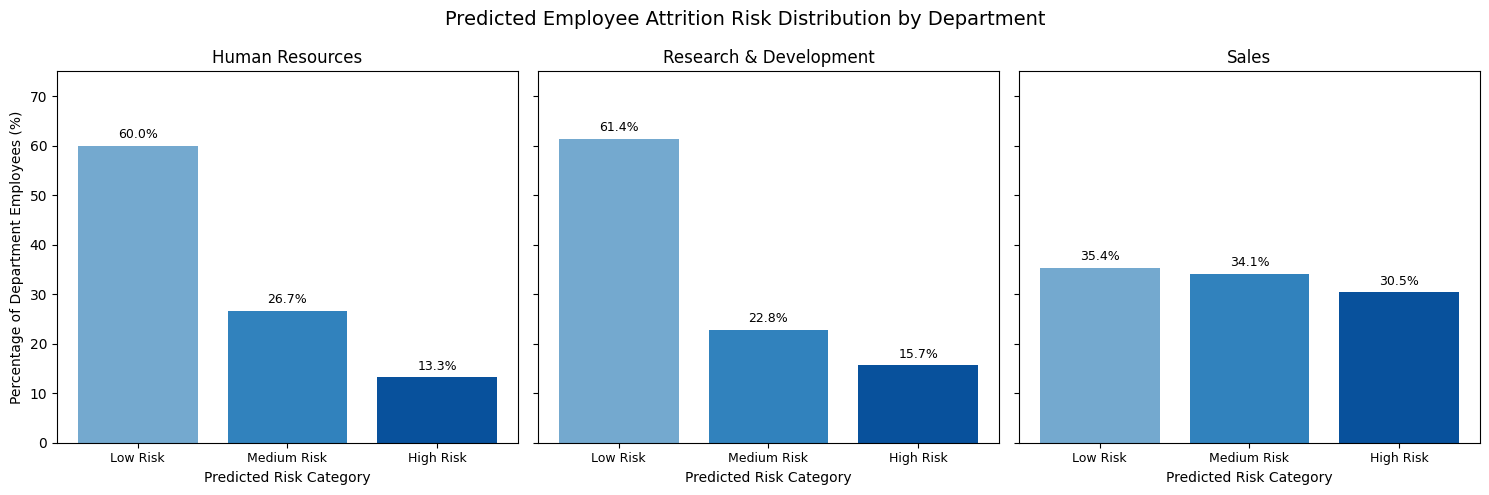

In [241]:

# Section 8.3 - Departmental Risk Distribution Chart

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

risk_categories = [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        department_risk[
            department_risk["Department"] == dept
        ]
        .set_index("Risk_Category")
        .reindex(risk_categories)
    )

    bars = ax.bar(
        risk_categories,
        data["Percentage_of_Department"],
        color=["#74A9CF", "#3182BD", "#08519C"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Category")
    ax.set_ylim(0, 75)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

    ax.tick_params(axis="x", labelsize=9)

axes[0].set_ylabel("Percentage of Department Employees (%)")

fig.suptitle(
    "Predicted Employee Attrition Risk Distribution by Department",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Human Resources:** 60.00% of employees were classified as Low Risk, 26.67% as Medium Risk and 13.33% as High Risk.
- **Research & Development:** 61.42% were classified as Low Risk, 22.84% as Medium Risk and 15.74% as High Risk.
- **Sales:** 35.37% were classified as Low Risk, 34.15% as Medium Risk and 30.49% as High Risk.
- Sales had the highest proportion of High Risk employees, approximately twice the proportion observed in Research & Development.
- The findings are consistent with the descriptive analysis in Section 6, where Sales recorded the highest overall employee attrition rate.

**Conclusion**

Sales emerged as the department with the highest concentration of predicted attrition risk, suggesting that it should be prioritised for further investigation into potential retention challenges.

Human Resources and Research & Development had larger proportions of employees classified as Low Risk.

These findings are based on the held-out testing dataset of 294 employees. Departmental differences, particularly for the small Human Resources sample, should be interpreted cautiously.


### 8.4 High-Risk Employee Profile Analysis

**Objective:** To identify common characteristics among employees classified as High Risk and examine how these characteristics differ across departments.

The analysis focuses on:

1. Overtime
2. Job Satisfaction
3. Monthly Income
4. Age

These factors were selected based on their predictive importance in Section 7.

The findings will help identify employee groups that may warrant further investigation and inform department-specific retention recommendations.

The analysis uses the held-out testing dataset. As these characteristics were also used to generate the risk predictions, the results describe model-identified risk profiles rather than independent evidence of the causes of attrition.

In [242]:

# Section 8.4 - High-Risk Employee Profile Analysis

import pandas as pd

# Select employees classified as High Risk
high_risk_df = risk_df[
    risk_df["Risk_Category"] == "High Risk"
].copy()

# Calculate high-risk profiles by department
high_risk_profile = (
    high_risk_df.groupby("Department")
    .agg(
        High_Risk_Employees=("Actual_Attrition", "count"),
        Employees_Left=("Actual_Attrition", "sum"),
        Overtime_Employees=("OverTime", lambda x: (x == "Yes").sum()),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Age=("Age", "mean"),
        Average_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .reset_index()
)

# Calculate percentage of high-risk employees working overtime
high_risk_profile["Overtime_Percentage"] = (
    high_risk_profile["Overtime_Employees"] /
    high_risk_profile["High_Risk_Employees"] * 100
)

# Convert predicted risk to percentage
high_risk_profile["Average_Predicted_Risk"] *= 100

# Round values
high_risk_profile = high_risk_profile.round(2)

print("High-Risk Employee Profiles by Department:")
display(high_risk_profile)


High-Risk Employee Profiles by Department:


,Department,High_Risk_Employees,Employees_Left,Overtime_Employees,Average_Job_Satisfaction,Median_Monthly_Income,Average_Age,Average_Predicted_Risk,Overtime_Percentage
0,Human Resources,2,1,2,2.00,2212.5,29.50,65.42,100.00
1,Research & Development,31,10,23,2.65,2725.0,29.10,43.55,74.19
2,Sales,25,12,17,2.72,3294.0,31.56,41.90,68.00


In [243]:

# Section 8.4 - Compare Employee Profiles Across Risk Categories

risk_profile_comparison = (
    risk_df.groupby(
        ["Department", "Risk_Category"],
        observed=True
    )
    .agg(
        Total_Employees=("Actual_Attrition", "count"),
        Overtime_Employees=("OverTime", lambda x: (x == "Yes").sum()),
        Average_Job_Satisfaction=("JobSatisfaction", "mean"),
        Median_Monthly_Income=("MonthlyIncome", "median"),
        Average_Age=("Age", "mean")
    )
    .reset_index()
)

# Calculate overtime percentage within each group
risk_profile_comparison["Overtime_Percentage"] = (
    risk_profile_comparison["Overtime_Employees"] /
    risk_profile_comparison["Total_Employees"] * 100
)

# Select columns for presentation
risk_profile_comparison = risk_profile_comparison[
    [
        "Department",
        "Risk_Category",
        "Total_Employees",
        "Overtime_Percentage",
        "Average_Job_Satisfaction",
        "Median_Monthly_Income",
        "Average_Age"
    ]
].round(2)

print("Employee Profiles by Department and Risk Category:")
display(risk_profile_comparison)


Employee Profiles by Department and Risk Category:


,Department,Risk_Category,Total_Employees,Overtime_Percentage,Average_Job_Satisfaction,Median_Monthly_Income,Average_Age
0,Human Resources,Low Risk,9,0.00,2.33,10482.0,43.67
1,Human Resources,Medium Risk,4,25.00,2.50,4259.5,31.75
2,Human Resources,High Risk,2,100.00,2.00,2212.5,29.50
3,Research & Development,Low Risk,121,5.79,2.89,5399.0,39.34
4,Research & Development,Medium Risk,45,40.00,2.49,3491.0,35.07
5,Research & Development,High Risk,31,74.19,2.65,2725.0,29.10
6,Sales,Low Risk,29,3.45,3.31,5736.0,38.79
7,Sales,Medium Risk,28,25.00,2.50,5356.0,36.86
8,Sales,High Risk,25,68.00,2.72,3294.0,31.56


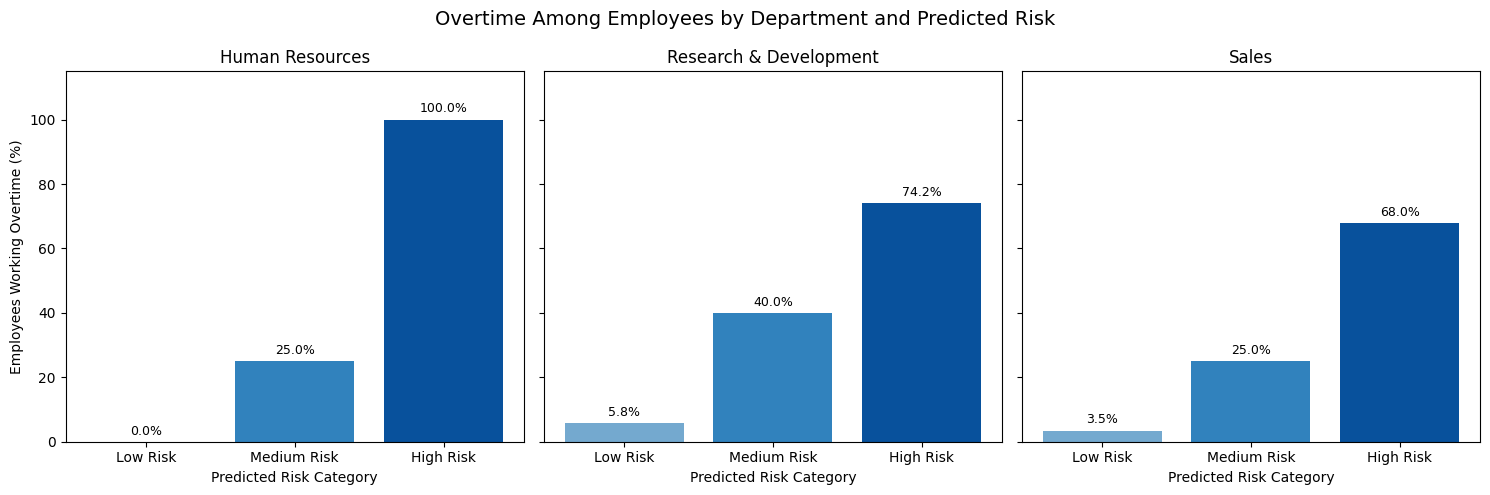

In [244]:

# Section 8.4 - Overtime by Department and Risk Category

import matplotlib.pyplot as plt

departments = [
    "Human Resources",
    "Research & Development",
    "Sales"
]

risk_categories = [
    "Low Risk",
    "Medium Risk",
    "High Risk"
]

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        risk_profile_comparison[
            risk_profile_comparison["Department"] == dept
        ]
        .set_index("Risk_Category")
        .reindex(risk_categories)
    )

    bars = ax.bar(
        risk_categories,
        data["Overtime_Percentage"],
        color=["#74A9CF", "#3182BD", "#08519C"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Category")
    ax.set_ylim(0, 115)

    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Employees Working Overtime (%)")

fig.suptitle(
    "Overtime Among Employees by Department and Predicted Risk",
    fontsize=14
)

plt.tight_layout()
plt.show()


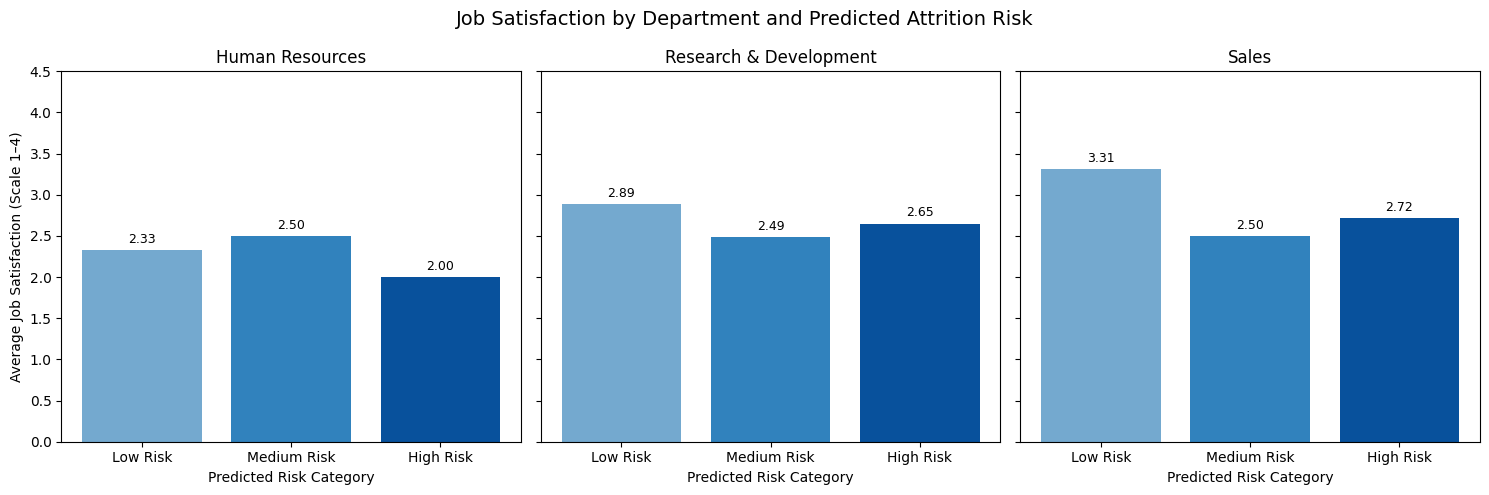

In [245]:

# Section 8.4 - Job Satisfaction by Department and Risk Category

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        risk_profile_comparison[
            risk_profile_comparison["Department"] == dept
        ]
        .set_index("Risk_Category")
        .reindex(risk_categories)
    )

    bars = ax.bar(
        risk_categories,
        data["Average_Job_Satisfaction"],
        color=["#74A9CF", "#3182BD", "#08519C"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Category")
    ax.set_ylim(0, 4.5)

    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Average Job Satisfaction (Scale 1–4)")

fig.suptitle(
    "Job Satisfaction by Department and Predicted Attrition Risk",
    fontsize=14
)

plt.tight_layout()
plt.show()


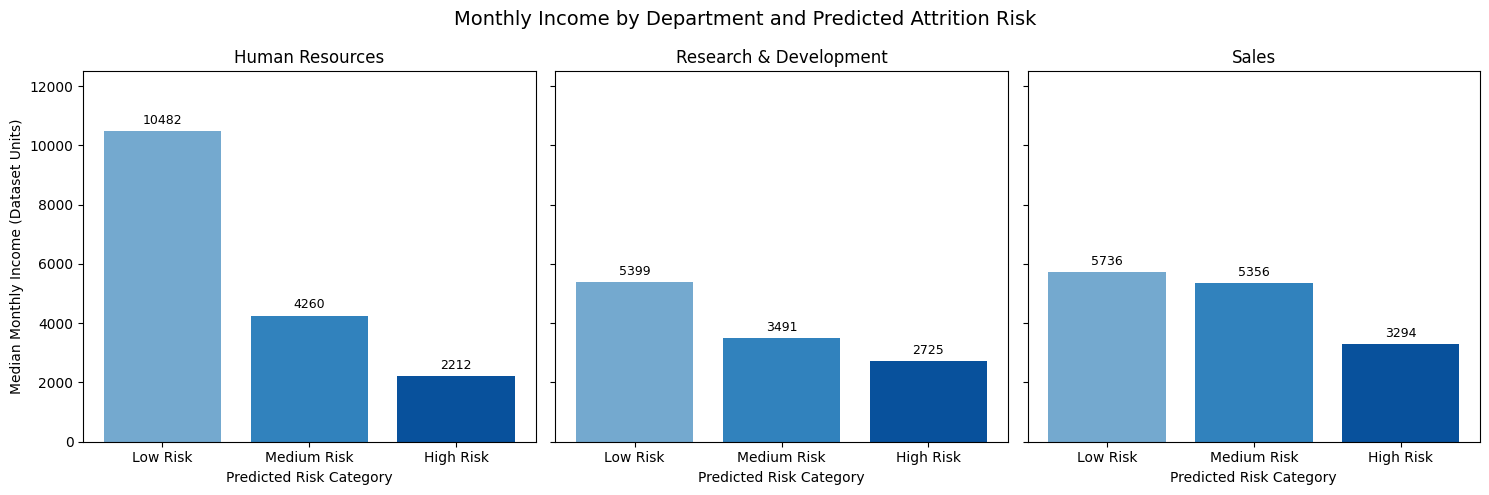

In [246]:

# Section 8.4 - Monthly Income by Department and Risk Category

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        risk_profile_comparison[
            risk_profile_comparison["Department"] == dept
        ]
        .set_index("Risk_Category")
        .reindex(risk_categories)
    )

    bars = ax.bar(
        risk_categories,
        data["Median_Monthly_Income"],
        color=["#74A9CF", "#3182BD", "#08519C"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Category")
    ax.set_ylim(0, 12500)

    ax.bar_label(
        bars,
        fmt="%.0f",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Median Monthly Income (Dataset Units)")

fig.suptitle(
    "Monthly Income by Department and Predicted Attrition Risk",
    fontsize=14
)

plt.tight_layout()
plt.show()


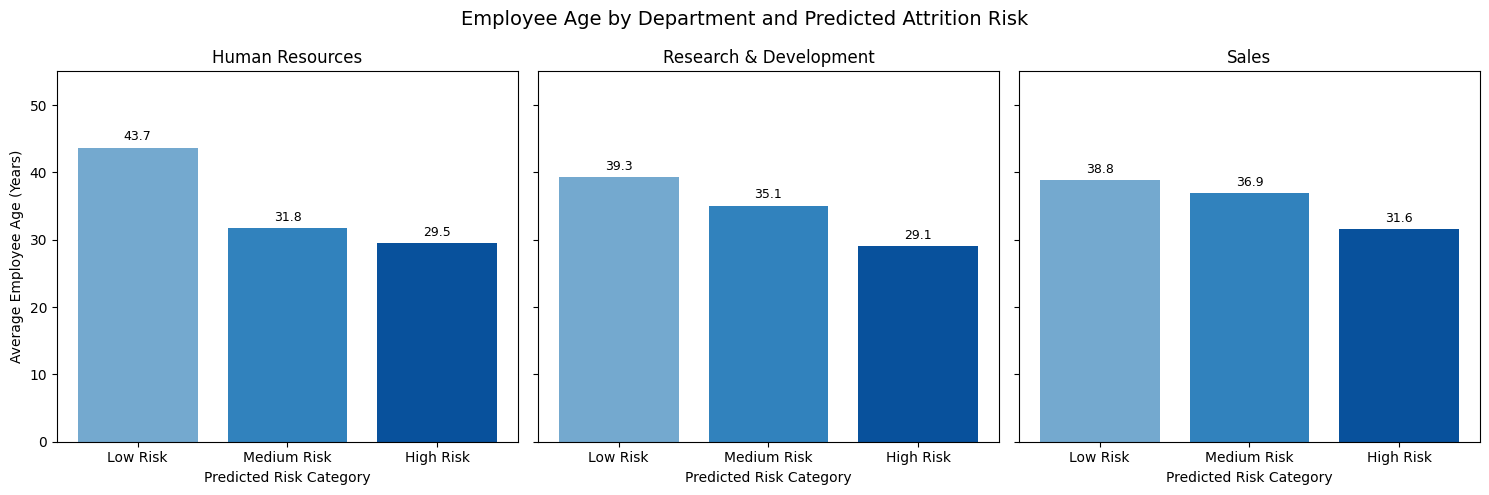

In [247]:

# Section 8.4 - Age by Department and Risk Category

fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 5),
    sharey=True
)

for ax, dept in zip(axes, departments):

    data = (
        risk_profile_comparison[
            risk_profile_comparison["Department"] == dept
        ]
        .set_index("Risk_Category")
        .reindex(risk_categories)
    )

    bars = ax.bar(
        risk_categories,
        data["Average_Age"],
        color=["#74A9CF", "#3182BD", "#08519C"]
    )

    ax.set_title(dept)
    ax.set_xlabel("Predicted Risk Category")
    ax.set_ylim(0, 55)

    ax.bar_label(
        bars,
        fmt="%.1f",
        padding=3,
        fontsize=9
    )

axes[0].set_ylabel("Average Employee Age (Years)")

fig.suptitle(
    "Employee Age by Department and Predicted Attrition Risk",
    fontsize=14
)

plt.tight_layout()
plt.show()



**Key Findings**

- **Overtime:** High Risk employees were more likely to work overtime across all departments. Overtime was reported by 74.19% of High Risk employees in R&D and 68.00% in Sales, compared with 5.79% and 3.45% respectively among Low Risk employees.
- **Job Satisfaction:** Low Risk employees generally reported higher average job satisfaction than High Risk employees. However, the relationship was not consistent across all risk categories.
- **Monthly Income:** High Risk employees had lower median monthly income across all three departments. In R&D, median income decreased from 5,399 among Low Risk employees to 2,725 among High Risk employees. In Sales, it decreased from 5,736 to 3,294.
- **Age:** High Risk employees were younger on average. Their average ages were 29.50 years in HR, 29.10 years in R&D and 31.56 years in Sales.
- **Departmental Priority:** Sales had the highest proportion of High Risk employees (30.49%), suggesting that it warrants closer investigation into potential retention challenges.

**Conclusion**

The High Risk employee profiles were characterised by a greater prevalence of overtime, generally lower job satisfaction, lower monthly income and younger average age.

These patterns provide useful areas for HR to investigate when developing targeted retention strategies.

However, these characteristics were also used as inputs to the predictive model. Therefore, the findings describe model-generated risk profiles and do not independently establish the causes of employee attrition.

The Human Resources findings should be interpreted cautiously because only two employees were classified as High Risk in the testing dataset.


## 9. HR Retention Recommendations

### Objective

To develop practical, data-driven HR recommendations that may help reduce employee attrition and support proactive workforce planning.

The recommendations are based on three areas of analysis:

1. **Descriptive Analytics (Section 6):** Identifying employee groups with higher observed attrition rates and understanding departmental patterns.
2. **Predictive Analytics (Section 7):** Identifying factors that contribute most to predicting employee attrition.
3. **Employee Attrition Risk Study (Section 8):** Identifying departments and employee groups with higher predicted attrition risk.

### Recommended HR Focus Areas

The analysis suggests four priority areas for further investigation and potential retention initiatives:

1. **Workload and Overtime Management**
2. **Employee Engagement and Job Satisfaction**
3. **Compensation and Career Development**
4. **Early-Career Employee Retention**

The recommendations will prioritise departments and employee groups where the findings indicate potential retention concerns.

As this project uses a synthetic HR dataset, the recommendations are illustrative. Further investigation and validation would be required before implementing them in an actual organisation.


### 9.1 Proposed HR Retention Strategies

Based on the descriptive and predictive analyses, the following retention strategies are recommended for further investigation and pilot implementation.

| Key Finding | Recommended HR Action | Departmental Priority | Success Measure |
|---|---|---|---|
| **1. Overtime is the strongest predictive factor.** Employees working overtime showed higher observed attrition across all departments. | Review overtime patterns, staffing levels and workload distribution. Introduce workload reviews and targeted staffing support where excessive overtime is identified. | **Sales and R&D:** Prioritise workload reviews. Include HR where overtime concerns are identified. | Overtime hours per employee; percentage of employees working overtime; attrition rate among employees working overtime. |
| **2. Job Satisfaction is the second most important predictive factor.** Lower satisfaction was generally associated with higher predicted attrition risk. | Conduct employee pulse surveys and structured feedback sessions. Identify workplace concerns and develop department-specific improvement plans with managers. | **Sales and R&D:** Prioritise teams reporting lower satisfaction or higher attrition. | Employee satisfaction score; survey participation rate; percentage of identified concerns addressed; employee attrition rate. |
| **3. Lower-income employee groups generally experienced higher attrition.** High Risk employees also had lower median monthly income. | Review compensation competitiveness and internal pay equity. Examine whether career progression, recognition and development opportunities meet employee expectations. | **Sales and R&D:** Review employee groups with higher observed attrition. | Attrition rate by income group; completion of compensation reviews; internal promotion rate; employee satisfaction with career opportunities. |
| **4. Younger and less-experienced employees showed higher attrition.** High Risk employees were also younger on average. | Strengthen onboarding, mentoring and early-career development. Introduce structured check-ins during the first year of employment and provide clearer career development pathways. | **All departments:** Prioritise early-career employees, with additional attention to Sales. | First-year attrition rate; retention at 6 and 12 months; mentoring participation; onboarding satisfaction. |
| **5. Sales had the highest observed attrition rate and highest proportion of High Risk employees.** | Conduct a focused Sales retention review covering workload, employee feedback, compensation and career development. Pilot suitable interventions and monitor results before wider implementation. | **Sales — Highest Priority** | Sales attrition rate; overtime trends; satisfaction score; 6- and 12-month retention rate. |

### Implementation Considerations

- HR should investigate the underlying reasons for attrition before implementing interventions.
- Recommended initiatives should be piloted and evaluated before organisation-wide rollout.
- Progress should be monitored through regular HR dashboards and management reviews.
- Predictive risk scores should support aggregate workforce planning and voluntary employee support, not be used as the sole basis for individual employment decisions.
- The effectiveness of retention initiatives should be assessed using actual employee outcomes over time.

**Expected Business Value**

These recommendations provide HR with a structured approach to identifying potential retention concerns, prioritising areas for investigation and monitoring whether targeted interventions are associated with improvements in employee retention.


### 9.2 Implementation Roadmap and Monitoring

**Objective:** To provide a structured approach for HR to investigate retention concerns, implement targeted initiatives and monitor their effectiveness.

| Phase | Timeline | Key Activities | Expected Output |
|---|---|---|---|
| **Phase 1: Investigate and Plan** | Months 1–2 | Review overtime, employee feedback, compensation and early-career attrition. Prioritise Sales for detailed investigation and establish baseline retention KPIs. | Identified retention concerns, baseline KPIs and agreed intervention plans. |
| **Phase 2: Pilot Retention Initiatives** | Months 3–6 | Pilot workload reviews, employee engagement initiatives, mentoring and career development support in selected teams. | Retention initiatives implemented, with participation and progress monitored. |
| **Phase 3: Evaluate and Improve** | Months 7–12 | Compare retention outcomes against baseline and, where feasible, suitable comparison groups. Review employee feedback, identify effective initiatives and refine the approach. | Evaluation findings and recommendations for continuation, adjustment or wider rollout. |

### Proposed Monitoring Indicators

| KPI | Purpose | Monitoring Frequency |
|---|---|---|
| Employee Attrition Rate | Monitor overall and departmental employee departures. | Quarterly |
| Overtime Hours per Employee | Identify sustained workload pressures. | Monthly |
| Employee Job Satisfaction Score | Monitor employee experience and workplace concerns. | Quarterly |
| First-Year Employee Retention Rate | Assess retention among newly recruited employees. | Quarterly |
| Retention at 6 and 12 Months | Monitor employee retention over time. | Quarterly |
| Retention Initiative Participation | Track implementation and employee engagement. | Monthly |

### Evaluation Approach

- Establish baseline KPIs before implementing retention initiatives.
- Monitor outcomes by department and relevant employee groups.
- Compare results over time and, where feasible, against comparable teams not participating in the pilot.
- Review employee feedback alongside quantitative indicators.
- Evaluate whether changes in retention are sustained before expanding initiatives.

### Limitations

The IBM HR dataset is synthetic and does not contain the longitudinal information needed to evaluate the effectiveness of retention interventions.

The proposed implementation roadmap is therefore illustrative. Actual effectiveness would need to be assessed using real organisational data collected over time.

Predictive risk scores should be used cautiously for aggregate workforce planning and supportive interventions, with appropriate privacy, fairness and human oversight.